In [1]:
import rasterio

#medium
##L1
# with rasterio.open("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif") as msrc, \
#      rasterio.open("/media/laura/laura_usb/uas_data/DD0001/lidar
with rasterio.open("/media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/imagery/dsm/SASMDD0011_dsm_pc_3cm.tif") as msrc, \
     rasterio.open("/media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/lidar/dsm/SASMDD0011_l1_dsm_03.tif") as lsrc:
    
##L2
# with rasterio.open("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif") as msrc, \
#      rasterio.open("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03.tif") as lsrc:
 
   
    
#low
# with rasterio.open("/media/laura/laura_usb/qgis/calperumResearch/site2_1_DD0011/lidar/sfm_dense/SASMDD0011_dsm_3cm.tif") as msrc, \
#      rasterio.open("/media/laura/Extreme SSD/qgis/calperumResearch/site2_1_DD0011/lidar/cloud2453cf90763afd91_DSM_3cm.tif") as lsrc:
    
    print("📏 MicaSense DSM shape:", msrc.height, "x", msrc.width)
    print("📏 LiDAR DEM shape    :", lsrc.height, "x", lsrc.width)
    print("🧭 MicaSense bounds   :", msrc.bounds)
    print("🧭 LiDAR bounds       :", lsrc.bounds)
    print("📐 MicaSense transform:", msrc.transform)
    print("📐 LiDAR transform    :", lsrc.transform)

📏 MicaSense DSM shape: 9478 x 8671
📏 LiDAR DEM shape    : 9623 x 6535
🧭 MicaSense bounds   : BoundingBox(left=473083.08966504433, bottom=6235597.58179418, right=473343.21966504434, top=6235881.92179418)
🧭 LiDAR bounds       : BoundingBox(left=473145.65999999986, bottom=6235616.839999774, right=473341.70999999985, top=6235905.529999774)
📐 MicaSense transform: | 0.03, 0.00, 473083.09|
| 0.00,-0.03, 6235881.92|
| 0.00, 0.00, 1.00|
📐 LiDAR transform    : | 0.03, 0.00, 473145.66|
| 0.00,-0.03, 6235905.53|
| 0.00, 0.00, 1.00|


In [2]:
import rasterio
import numpy as np

print("=" * 80)
print("NODATA HARMONIZATION ANALYSIS")
print("=" * 80)

lidar_original = "/media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/lidar/dsm/SASMDD0011_l1_dsm_03.tif"
imagery_template = "/media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/lidar/dsm/SASMDD0011_l1_dsm_03.tif"
lidar_resampled = "/media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/lidar/dsm/crop_to_rgb/SASMDD0011_l1_dsm_03.tif"

print("\n📊 SUMMARY:")
print(f"  RGB DSM nodata:       -32767.0 (template)")
print(f"  LiDAR DSM nodata:     -9999.0  (source)")
print(f"  Resampled nodata:     -9999.0  (preserved from source)")

print("\n" + "=" * 80)
print("RECOMMENDATIONS:")
print("=" * 80)
print("1. ✅ Current approach is FINE if you're using masked arrays")
print("   The load_data_and_mask() function handles different nodata values")
print("   by converting them to boolean masks.")
print()
print("2. 🔧 OPTIONAL: Harmonize nodata values if needed:")
print("   You could standardize both to use -9999.0 or -32767.0")
print()
print("3. ⚠️ For GeFolki flow calculation:")
print("   Make sure your mask creation uses the correct nodata value:")
print("   - RGB mask:   data != -32767.0")
print("   - LiDAR mask: data != -9999.0")
print("=" * 80)

# Check if masks will work correctly
print("\n🔍 MASK VALIDATION:")
with rasterio.open(imagery_template) as src:
    rgb_data = src.read(1)
    rgb_mask_internal = src.read_masks(1) > 0  # Internal mask
    rgb_mask_manual = rgb_data != -32767.0     # Manual mask
    print(f"  RGB - Internal mask pixels: {rgb_mask_internal.sum():,}")
    print(f"  RGB - Manual mask pixels:   {rgb_mask_manual.sum():,}")
    print(f"  Match: {np.array_equal(rgb_mask_internal, rgb_mask_manual)}")

with rasterio.open(lidar_resampled) as src:
    lidar_data = src.read(1)
    lidar_mask_internal = src.read_masks(1) > 0
    lidar_mask_manual = lidar_data != -9999.0
    print(f"\n  LiDAR - Internal mask pixels: {lidar_mask_internal.sum():,}")
    print(f"  LiDAR - Manual mask pixels:   {lidar_mask_manual.sum():,}")
    print(f"  Match: {np.array_equal(lidar_mask_internal, lidar_mask_manual)}")

print("\n" + "=" * 80)
print("CONCLUSION:")
print("=" * 80)
print("Your current workflow is correct! The different nodata values")
print("(-32767 vs -9999) are not a problem because:")
print("  1. Each file internally tracks its own nodata value")
print("  2. read_masks() automatically handles this")
print("  3. Your GeFolki preprocessing uses src.read_masks() correctly")
print("=" * 80)

NODATA HARMONIZATION ANALYSIS

📊 SUMMARY:
  RGB DSM nodata:       -32767.0 (template)
  LiDAR DSM nodata:     -9999.0  (source)
  Resampled nodata:     -9999.0  (preserved from source)

RECOMMENDATIONS:
1. ✅ Current approach is FINE if you're using masked arrays
   The load_data_and_mask() function handles different nodata values
   by converting them to boolean masks.

2. 🔧 OPTIONAL: Harmonize nodata values if needed:
   You could standardize both to use -9999.0 or -32767.0

3. ⚠️ For GeFolki flow calculation:
   Make sure your mask creation uses the correct nodata value:
   - RGB mask:   data != -32767.0
   - LiDAR mask: data != -9999.0

🔍 MASK VALIDATION:
  RGB - Internal mask pixels: 52,155,796
  RGB - Manual mask pixels:   62,886,305
  Match: False

  LiDAR - Internal mask pixels: 49,697,006
  LiDAR - Manual mask pixels:   49,697,006
  Match: True

CONCLUSION:
Your current workflow is correct! The different nodata values
(-32767 vs -9999) are not a problem because:
  1. Each file 

In [ ]:
### GOOD: better resampling
import os
import rasterio
from rasterio.warp import reproject, Resampling
import numpy as np

def create_raster_with_reference_shape(
    source_data_path: str, 
    template_grid_path: str, 
    destination_path: str, 
    resampling_method=Resampling.bilinear
):
    """
    Creates a new raster file with the exact shape and grid of a template raster.

    This function reads the pixel values from the source raster and resamples them
    to fit perfectly onto the grid defined by the template raster. The output file
    will have the exact same dimensions (height/width), CRS, and extent as the
    template file. Both input files remain unchanged.

    Args:
        source_data_path (str): Path to the raster providing the pixel values (e.g., LiDAR DSM).
        template_grid_path (str): Path to the raster providing the target grid/shape (e.g., imagery DSM).
        destination_path (str): Path where the new, aligned raster will be saved.
        resampling_method (Resampling, optional): The algorithm for resampling.
            Defaults to Resampling.bilinear.
    """
    print("--- Creating New Raster with Template Shape ---")
    print(f"Source of Data:   '{source_data_path}'")
    print(f"Template for Grid:  '{template_grid_path}'")
    print(f"New Output File:    '{destination_path}'")

    # Ensure the output directory exists.
    output_dir = os.path.dirname(destination_path)
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
        print(f"Created output directory: {output_dir}")

    # 1. Open the template file to get its grid definition (profile).
    # This file is ONLY READ FROM, never written to.
    with rasterio.open(template_grid_path) as template_ds:
        template_profile = template_ds.profile
        
    # 2. Open the source data file.
    # This file is also ONLY READ FROM.
    with rasterio.open(source_data_path) as source_ds:
        
        # 3. Define the metadata for our NEW output file.
        # It's a copy of the template's grid, but we'll use the
        # data type (e.g., float32) and nodata value from our source data.
        output_profile = template_profile.copy()
        output_profile.update({
            'dtype': source_ds.profile.get('dtype', 'float32'),
            'nodata': source_ds.nodata
        })

        # 4. Create an empty placeholder array. This array has the exact
        # dimensions of our template raster.
        destination_array = np.empty(
            (template_profile['height'], template_profile['width']), 
            dtype=output_profile['dtype']
        )

        # 5. This is the core step. 'reproject' takes the data from the source,
        # transforms it in memory, and fills our placeholder array.
        reproject(
            source=rasterio.band(source_ds, 1),
            destination=destination_array,
            src_transform=source_ds.transform,
            src_crs=source_ds.crs,
            dst_transform=template_profile['transform'],
            dst_crs=template_profile['crs'],
            resampling=resampling_method
        )
        
        # 6. Save the new array to the destination file with the correct profile.
        with rasterio.open(destination_path, 'w', **output_profile) as dst:
            dst.write(destination_array, 1)

    print(f"\n✅ Success! New raster created at '{destination_path}' with the exact shape of the reference file.")


if __name__ == "__main__":
    # --- Define file paths ---
    #l1
    # lidar_dsm_path = "/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif"
    lidar_dsm_path = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif"
    #l2
    # lidar_dsm_path = "/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/SASMDD0001_l2_dsm_03.tif"
    
    # imagery_dsm_path = "/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif"
    imagery_dsm_path = "/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif"
    
    # The final output file path.
    # output_path = "/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif"
    output_path = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif"
    
    # output_path = "/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_l1/SASMDD0001_l2_dsm_03.tif"


    # --- Run the process ---
    if not os.path.exists(lidar_dsm_path):
        print(f"Error: Source data file not found at: {lidar_dsm_path}")
    elif not os.path.exists(imagery_dsm_path):
        print(f"Error: Template grid file not found at: {imagery_dsm_path}")
    else:
        create_raster_with_reference_shape(
            source_data_path=lidar_dsm_path,
            template_grid_path=imagery_dsm_path,
            destination_path=output_path
        )

--- Creating New Raster with Template Shape ---
Source of Data:   '/data/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif'
Template for Grid:  '/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif'
New Output File:    '/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif'

✅ Success! New raster created at '/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif' with the exact shape of the reference file.


In [3]:
import rasterio

#medium
##L1
# with rasterio.open("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif") as msrc, \
#      rasterio.open("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif") as lsrc:

with rasterio.open("/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif") as msrc, \
     rasterio.open("/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif") as lsrc:
    
##L2
# with rasterio.open("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif") as msrc, \
#      rasterio.open("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03.tif") as lsrc:

# with rasterio.open("/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif") as msrc, \
#      rasterio.open("/data/calperumResearch/site1_1_DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03.tif") as lsrc:
   
    
#low
# with rasterio.open("/media/laura/laura_usb/qgis/calperumResearch/site2_1_DD0011/lidar/sfm_dense/SASMDD0011_dsm_3cm.tif") as msrc, \
#      rasterio.open("/media/laura/Extreme SSD/qgis/calperumResearch/site2_1_DD0011/lidar/cloud2453cf90763afd91_DSM_3cm.tif") as lsrc:

#L1
# with rasterio.open("/data/calperumResearch/site2_1_DD0011/imagery/dsm/SASMDD0011_rgb_dsm_03.tif") as msrc, \
#      rasterio.open("/data/calperumResearch/site2_1_DD0011/lidar/dsm/crop_to_rgb/SASMDD0011_l1_dsm_03.tif") as lsrc:

#L2  
# with rasterio.open("/data/calperumResearch/site2_1_DD0011/imagery/dsm/SASMDD0011_rgb_dsm_03.tif") as msrc, \
#      rasterio.open("/data/calperumResearch/site2_1_DD0011/lidar_l2/dsm/crop_to_rgb/SASMDD0011_l2_dsm_03.tif") as lsrc:
    
    print("📏 MicaSense DSM shape:", msrc.height, "x", msrc.width)
    print("📏 LiDAR DEM shape    :", lsrc.height, "x", lsrc.width)
    print("🧭 MicaSense bounds   :", msrc.bounds)
    print("🧭 LiDAR bounds       :", lsrc.bounds)
    print("📐 MicaSense transform:", msrc.transform)
    print("📐 LiDAR transform    :", lsrc.transform)

📏 MicaSense DSM shape: 14380 x 14314
📏 LiDAR DEM shape    : 14380 x 14314
🧭 MicaSense bounds   : BoundingBox(left=461649.36835590197, bottom=6237319.415841555, right=462078.78835590195, top=6237750.815841556)
🧭 LiDAR bounds       : BoundingBox(left=461649.36835590197, bottom=6237319.415841555, right=462078.78835590195, top=6237750.815841556)
📐 MicaSense transform: | 0.03, 0.00, 461649.37|
| 0.00,-0.03, 6237750.82|
| 0.00, 0.00, 1.00|
📐 LiDAR transform    : | 0.03, 0.00, 461649.37|
| 0.00,-0.03, 6237750.82|
| 0.00, 0.00, 1.00|


## Before/After Shape Comparison

In [1]:
import rasterio

print("=" * 80)
print("BEFORE/AFTER RASTER SHAPE COMPARISON")
print("=" * 80)

# Site 1, L1 example
lidar_original = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif"
imagery_template = "/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif"
lidar_resampled = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif"

print("\n📊 BEFORE RESAMPLING:")
with rasterio.open(lidar_original) as src:
    print(f"   LiDAR DSM:    {src.height} × {src.width} pixels")
    print(f"   Bounds:       {src.bounds}")
    print(f"   Transform:    {src.transform}")

with rasterio.open(imagery_template) as src:
    print(f"   Imagery DSM:  {src.height} × {src.width} pixels (target)")
    print(f"   Bounds:       {src.bounds}")
    print(f"   Transform:    {src.transform}")

print("\n📊 AFTER RESAMPLING:")
try:
    with rasterio.open(lidar_resampled) as src:
        print(f"   LiDAR DSM:    {src.height} × {src.width} pixels ✅ MATCHED")
        print(f"   Bounds:       {src.bounds}")
        print(f"   Transform:    {src.transform}")
        
    with rasterio.open(imagery_template) as template, \
         rasterio.open(lidar_resampled) as resampled:
        if (template.height == resampled.height and 
            template.width == resampled.width and
            template.bounds == resampled.bounds):
            print("\n✅ SUCCESS: Shapes and bounds match perfectly!")
        else:
            print("\n⚠️ WARNING: Shapes or bounds don't match!")
            
except FileNotFoundError:
    print("   ⚠️ Resampled file not yet created. Run the resampling cell first.")

print("=" * 80)

BEFORE/AFTER RASTER SHAPE COMPARISON

📊 BEFORE RESAMPLING:
   LiDAR DSM:    15933 × 13234 pixels
   Bounds:       BoundingBox(left=461661.6499999113, bottom=6237294.869999838, right=462058.66999991133, top=6237772.859999838)
   Transform:    | 0.03, 0.00, 461661.65|
| 0.00,-0.03, 6237772.86|
| 0.00, 0.00, 1.00|
   Imagery DSM:  14380 × 14314 pixels (target)
   Bounds:       BoundingBox(left=461649.36835590197, bottom=6237319.415841555, right=462078.78835590195, top=6237750.815841556)
   Transform:    | 0.03, 0.00, 461649.37|
| 0.00,-0.03, 6237750.82|
| 0.00, 0.00, 1.00|

📊 AFTER RESAMPLING:
   LiDAR DSM:    14380 × 14314 pixels ✅ MATCHED
   Bounds:       BoundingBox(left=461649.36835590197, bottom=6237319.415841555, right=462078.78835590195, top=6237750.815841556)
   Transform:    | 0.03, 0.00, 461649.37|
| 0.00,-0.03, 6237750.82|
| 0.00, 0.00, 1.00|

✅ SUCCESS: Shapes and bounds match perfectly!


## Visual Comparison

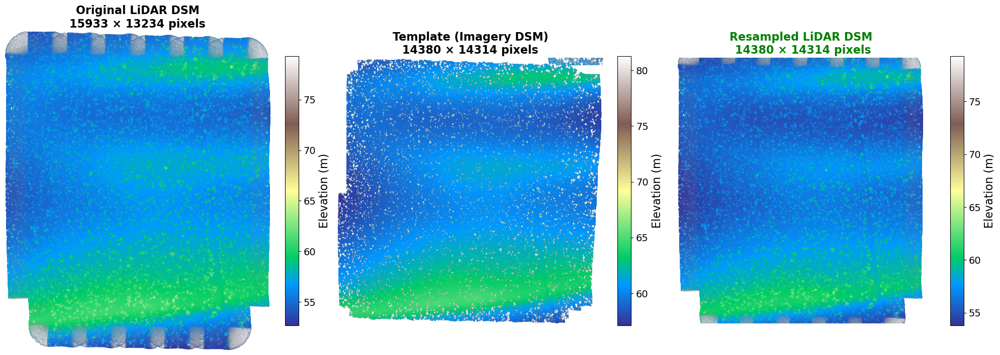


💡 The resampled DSM should have the exact same dimensions as the template.


In [ ]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

# File paths
lidar_original = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif"
imagery_template = "/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif"
lidar_resampled = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif"

def get_global_minmax(paths, pmin=2, pmax=98):
    vals = []
    for p in paths:
        with rasterio.open(p) as src:
            arr = src.read(1, masked=True)
            vals.append(arr.compressed())
    all_vals = np.concatenate(vals)
    return np.percentile(all_vals, pmin), np.percentile(all_vals, pmax)

vmin, vmax = get_global_minmax([
    lidar_original,
    imagery_template,
    lidar_resampled
])


fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# 1. Original LiDAR DSM
with rasterio.open(lidar_original) as src:
    data = src.read(1)
    data = np.ma.masked_equal(data, src.nodata) if src.nodata else data
    
    im1 = axes[0].imshow(data, cmap='terrain', vmin=vmin, vmax=vmax)

    # axes[0].set_title(f'Original LiDAR DSM\n{src.height} × {src.width} pixels', 
    #                   fontsize=16, fontweight='bold')
    # plt.colorbar(im1, ax=axes[0], label='Elevation (m)', fraction=0.046)
    cbar = plt.colorbar(im1, ax=axes[0], fraction=0.046)
    cbar.set_label("Elevation (m)", fontsize=16)
    cbar.ax.tick_params(labelsize=14)
    axes[0].axis('off')

# 2. Template (Imagery DSM)
with rasterio.open(imagery_template) as src:
    data = src.read(1)
    data = np.ma.masked_equal(data, src.nodata) if src.nodata else data
    
    im2 = axes[1].imshow(data, cmap='terrain', vmin=vmin, vmax=vmax)

    # axes[1].set_title(f'Template (Imagery DSM)\n{src.height} × {src.width} pixels', 
                    #   fontsize=16, fontweight='bold')
    # plt.colorbar(im2, ax=axes[1], label='Elevation (m)', fraction=0.046)
    cbar = plt.colorbar(im2, ax=axes[1], fraction=0.046)
    cbar.set_label("Elevation (m)", fontsize=16)
    cbar.ax.tick_params(labelsize=14)
    axes[1].axis('off')

# 3. Resampled LiDAR DSM
try:
    with rasterio.open(lidar_resampled) as src:
        data = src.read(1)
        data = np.ma.masked_equal(data, src.nodata) if src.nodata else data
        
        im3 = axes[2].imshow(data, cmap='terrain', vmin=vmin, vmax=vmax)

        axes[2].set_title(f'Resampled LiDAR DSM \n{src.height} × {src.width} pixels', 
                          fontsize=16, fontweight='bold', color='green')
        # plt.colorbar(im3, ax=axes[2], label='Elevation (m)', fraction=0.046)
        cbar = plt.colorbar(im3, ax=axes[2], fraction=0.046)
        cbar.set_label("Elevation (m)", fontsize=16)
        cbar.ax.tick_params(labelsize=14)
        axes[2].axis('off')
except FileNotFoundError:
    axes[2].text(0.5, 0.5, '⚠️ Resampled file not found\nRun resampling cell first', 
                ha='center', va='center', transform=axes[2].transAxes, 
                fontsize=14, color='red')
    # axes[2].set_title('Resampled LiDAR DSM', fontsize=16, fontweight='bold')
    axes[2].axis('off')

plt.tight_layout()
plt.show()

print("\n💡 The resampled DSM should have the exact same dimensions as the template.")

lidar_corrected: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg.tif
flow_u_path: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/dsm/flow_u_03_l1.npy
flow_v_path: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/dsm/flow_v_03_l1.npy


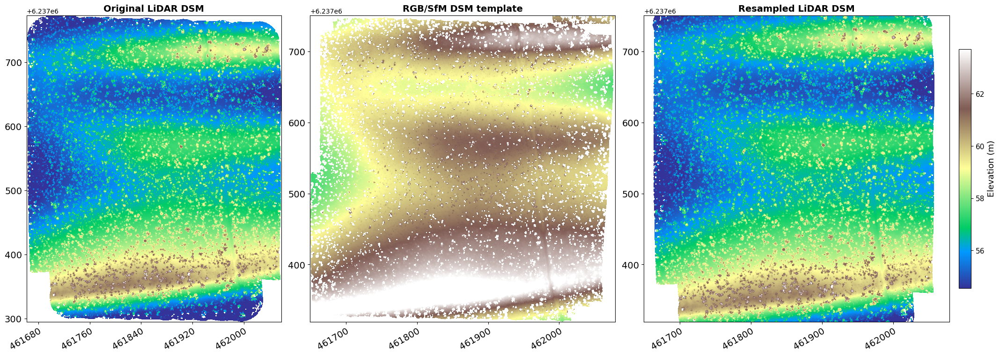

Saved: figures/dsm_grid_standardisation_before_gefolki.png


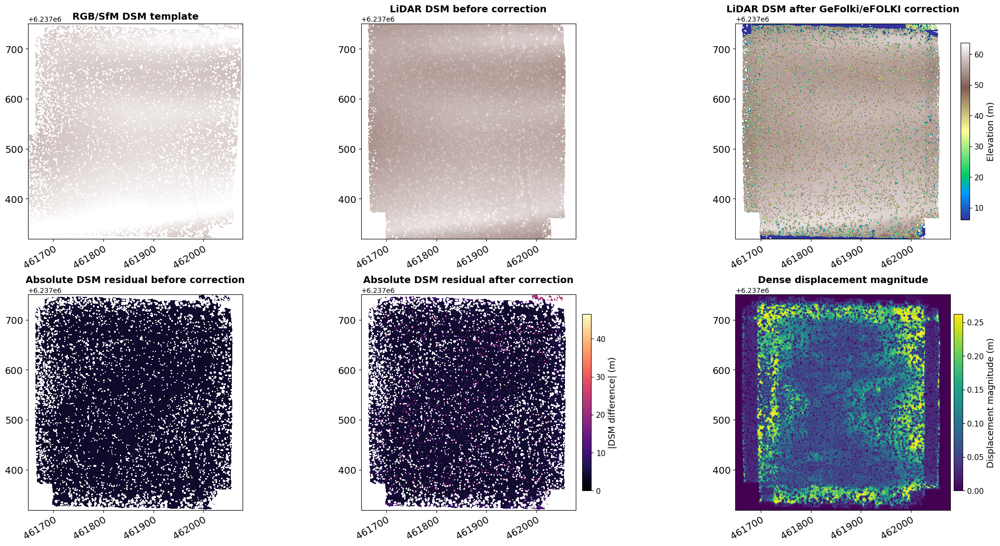

Saved: figures/gefolki_coregistration_before_after.png


In [8]:
from pathlib import Path

import numpy as np
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


# ---------------------------------------------------------------------
# File paths
# ---------------------------------------------------------------------
lidar_original = "/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif"
imagery_template = "/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif"
lidar_resampled = "/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif"

# Optional explicit override. Leave as None to auto-resolve from common names.
lidar_corrected = None

# Optional explicit flow-field paths. Leave as None to auto-resolve common names.
flow_u_path = None
flow_v_path = None

# Use "pixels" if u and v are pixel displacement fields.
# Use "metres" if they have already been converted to metric displacement.
FLOW_UNITS = "pixels"


# ---------------------------------------------------------------------
# Output and style settings
# ---------------------------------------------------------------------
out_dir = Path("figures")
out_dir.mkdir(parents=True, exist_ok=True)

MAX_DIM = 3000  # Downsample only for plotting large rasters.

TITLE_SIZE = 14
TICK_SIZE = 14
CBAR_LABEL_SIZE = 13
CBAR_TICK_SIZE = 11
X_TICK_ROTATION = 30

FIG1_SIZE = (22, 7.5)
FIG2_SIZE = (22, 11)


# ---------------------------------------------------------------------
# Helper functions
# ---------------------------------------------------------------------
def path_exists(path):
    """Return True if path is not None and exists."""
    return path is not None and Path(path).exists()


def first_existing(paths):
    """Return the first existing path from a list of candidate paths."""
    for path in paths:
        if path is not None and Path(path).exists():
            return str(path)
    return None


def raster_extent_from_meta(meta):
    """
    Convert raster metadata into matplotlib extent:
    (left, right, bottom, top).
    """
    transform = meta["transform"]
    width = meta["width"]
    height = meta["height"]

    left = transform.c
    top = transform.f
    right = left + width * transform.a
    bottom = top + height * transform.e

    return (left, right, bottom, top)


def read_raster_for_plot(
    path,
    out_shape=None,
    max_dim=MAX_DIM,
    resampling=Resampling.bilinear,
):
    """
    Read a raster as a masked float32 array.

    Large rasters are downsampled for visualisation only.
    The original raster files are not modified.
    """
    path = Path(path)

    with rasterio.open(path) as src:
        if out_shape is None:
            if max(src.height, src.width) > max_dim:
                scale = max(src.height, src.width) / max_dim
                out_height = int(round(src.height / scale))
                out_width = int(round(src.width / scale))
                out_shape = (out_height, out_width)
            else:
                out_shape = (src.height, src.width)

        arr = src.read(
            1,
            masked=True,
            out_shape=out_shape,
            resampling=resampling,
        ).astype("float32")

        arr = np.ma.masked_invalid(arr)

        meta = {
            "height": src.height,
            "width": src.width,
            "transform": src.transform,
            "crs": src.crs,
            "res": src.res,
            "nodata": src.nodata,
        }

    return arr, meta


def robust_limits_from_arrays(arrays, pmin=2, pmax=98):
    """
    Compute robust colour limits from a list of arrays using percentiles.
    """
    vals = []

    for arr in arrays:
        if arr is None:
            continue

        if isinstance(arr, np.ma.MaskedArray):
            v = arr.compressed()
        else:
            v = np.asarray(arr).ravel()
            v = v[np.isfinite(v)]

        if v.size > 0:
            vals.append(v)

    if not vals:
        raise ValueError("No valid values available for percentile limits.")

    vals = np.concatenate(vals)
    return float(np.percentile(vals, pmin)), float(np.percentile(vals, pmax))


def robust_limits_from_paths(paths, pmin=2, pmax=98, max_dim=1500):
    """
    Compute robust colour limits from raster paths.
    """
    arrays = []

    for path in paths:
        if path_exists(path):
            arr, _ = read_raster_for_plot(path, max_dim=max_dim)
            arrays.append(arr)

    return robust_limits_from_arrays(arrays, pmin=pmin, pmax=pmax)


def read_array_or_raster(path, out_shape=None):
    """
    Read a GeoTIFF, .npy, or .npz displacement field for plotting.
    """
    path = Path(path)
    suffix = path.suffix.lower()

    if suffix in [".tif", ".tiff"]:
        arr, _ = read_raster_for_plot(path, out_shape=out_shape)
        return arr

    if suffix == ".npy":
        arr = np.load(path).astype("float32")
        arr = np.ma.masked_invalid(arr)

    elif suffix == ".npz":
        npz = np.load(path)
        first_key = npz.files[0]
        arr = npz[first_key].astype("float32")
        arr = np.ma.masked_invalid(arr)

    else:
        raise ValueError(f"Unsupported flow-field format: {suffix}")

    if out_shape is not None and arr.shape != out_shape:
        sy = max(1, int(round(arr.shape[0] / out_shape[0])))
        sx = max(1, int(round(arr.shape[1] / out_shape[1])))
        arr = arr[::sy, ::sx]
        arr = arr[: out_shape[0], : out_shape[1]]

    return arr


def style_map_axis(
    ax,
    extent,
    tick_size=TICK_SIZE,
    nbins=5,
    x_rotation=X_TICK_ROTATION,
):
    """
    Apply consistent axis limits, tick density, font size, and x-axis rotation.
    """
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])

    ax.xaxis.set_major_locator(MaxNLocator(nbins=nbins))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=nbins))

    ax.tick_params(axis="both", labelsize=tick_size)

    for label in ax.get_xticklabels():
        label.set_rotation(x_rotation)
        label.set_ha("right")
        label.set_rotation_mode("anchor")
        label.set_fontsize(tick_size)

    for label in ax.get_yticklabels():
        label.set_fontsize(tick_size)


def style_colorbar(cbar, label):
    """
    Apply consistent colourbar font sizes.
    """
    cbar.set_label(label, fontsize=CBAR_LABEL_SIZE)
    cbar.ax.tick_params(labelsize=CBAR_TICK_SIZE)


# ---------------------------------------------------------------------
# Auto-resolve corrected DSM and flow fields
# ---------------------------------------------------------------------
lidar_resampled_path = Path(lidar_resampled)

stem = lidar_resampled_path.stem
crop_dir = lidar_resampled_path.parent
dsm_dir = crop_dir.parent
site_dir = dsm_dir.parent.parent
imagery_dsm_dir = Path(imagery_template).parent

if not path_exists(lidar_corrected):
    lidar_corrected = first_existing(
        [
            crop_dir / f"{stem}_coreg.tif",
            crop_dir / f"{stem}_gefolki.tif",
            dsm_dir / "coregistered" / f"{stem}_coreg.tif",
            dsm_dir / "coregistered" / f"{stem}_gefolki.tif",
            dsm_dir / f"{stem}_coreg.tif",
            dsm_dir / f"{stem}_gefolki.tif",
        ]
    )

if not path_exists(flow_u_path):
    flow_u_path = first_existing(
        [
            imagery_dsm_dir / "flow_u_03_l1.npy",
            imagery_dsm_dir / "flow_u_03.npy",
            site_dir / "imagery" / "dsm" / "flow_u_03_l1.npy",
            site_dir / "imagery" / "dsm" / "flow_u_03.npy",
        ]
    )

if not path_exists(flow_v_path):
    flow_v_path = first_existing(
        [
            imagery_dsm_dir / "flow_v_03_l1.npy",
            imagery_dsm_dir / "flow_v_03.npy",
            site_dir / "imagery" / "dsm" / "flow_v_03_l1.npy",
            site_dir / "imagery" / "dsm" / "flow_v_03.npy",
        ]
    )

print("lidar_corrected:", lidar_corrected)
print("flow_u_path:", flow_u_path)
print("flow_v_path:", flow_v_path)


# ---------------------------------------------------------------------
# Figure 1: DSM grid standardisation / resampling
# ---------------------------------------------------------------------
vmin, vmax = robust_limits_from_paths(
    [lidar_original, imagery_template, lidar_resampled],
    pmin=2,
    pmax=98,
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=FIG1_SIZE,
    constrained_layout=True,
)

panels = [
    (lidar_original, "Original LiDAR DSM"),
    (imagery_template, "RGB/SfM DSM template"),
    (lidar_resampled, "Resampled LiDAR DSM"),
]

last_im = None

for ax, (path, title) in zip(axes, panels):
    arr, meta = read_raster_for_plot(path)
    extent = raster_extent_from_meta(meta)

    last_im = ax.imshow(
        arr,
        cmap="terrain",
        vmin=vmin,
        vmax=vmax,
        extent=extent,
        origin="upper",
    )

    ax.set_title(
        title,
        fontsize=TITLE_SIZE,
        fontweight="bold",
    )

    style_map_axis(
        ax,
        extent,
        tick_size=TICK_SIZE,
        nbins=5,
        x_rotation=X_TICK_ROTATION,
    )

cbar = fig.colorbar(
    last_im,
    ax=axes.ravel().tolist(),
    shrink=0.78,
    pad=0.01,
)

style_colorbar(cbar, "Elevation (m)")

fig_path = out_dir / "dsm_grid_standardisation_before_gefolki.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {fig_path}")


# ---------------------------------------------------------------------
# Figure 2: GeFolki/eFOLKI co-registration evidence
# ---------------------------------------------------------------------
if path_exists(lidar_corrected):
    with rasterio.open(imagery_template) as src:
        if max(src.height, src.width) > MAX_DIM:
            scale = max(src.height, src.width) / MAX_DIM
            out_shape = (
                int(round(src.height / scale)),
                int(round(src.width / scale)),
            )
        else:
            out_shape = (src.height, src.width)

        pixel_width = abs(src.transform.a)
        pixel_height = abs(src.transform.e)

    template, template_meta = read_raster_for_plot(
        imagery_template,
        out_shape=out_shape,
    )

    before, _ = read_raster_for_plot(
        lidar_resampled,
        out_shape=out_shape,
    )

    after, _ = read_raster_for_plot(
        lidar_corrected,
        out_shape=out_shape,
    )

    plot_extent = raster_extent_from_meta(template_meta)

    elev_vmin, elev_vmax = robust_limits_from_arrays(
        [template, before, after],
        pmin=2,
        pmax=98,
    )

    residual_before = np.ma.abs(before - template)
    residual_after = np.ma.abs(after - template)

    _, residual_vmax = robust_limits_from_arrays(
        [residual_before, residual_after],
        pmin=2,
        pmax=98,
    )

    has_flow = path_exists(flow_u_path) and path_exists(flow_v_path)

    if has_flow:
        u = read_array_or_raster(flow_u_path, out_shape=out_shape)
        v = read_array_or_raster(flow_v_path, out_shape=out_shape)

        if FLOW_UNITS.lower() == "pixels":
            displacement = np.ma.sqrt(
                (u * pixel_width) ** 2 + (v * pixel_height) ** 2
            )
            displacement_label = "Displacement magnitude (m)"
        else:
            displacement = np.ma.sqrt(u**2 + v**2)
            displacement_label = "Displacement magnitude (m)"

        _, displacement_vmax = robust_limits_from_arrays(
            [displacement],
            pmin=2,
            pmax=98,
        )
    else:
        displacement = None
        displacement_vmax = None
        displacement_label = "Displacement magnitude"

    fig, axes = plt.subplots(
        2,
        3,
        figsize=FIG2_SIZE,
        constrained_layout=True,
    )

    # -----------------------------------------------------------------
    # Top row: DSM surfaces
    # -----------------------------------------------------------------
    elevation_panels = [
        (template, "RGB/SfM DSM template"),
        (before, "LiDAR DSM before correction"),
        (after, "LiDAR DSM after GeFolki/eFOLKI correction"),
    ]

    im_elev = None

    for ax, (arr, title) in zip(axes[0, :], elevation_panels):
        im_elev = ax.imshow(
            arr,
            cmap="terrain",
            vmin=elev_vmin,
            vmax=elev_vmax,
            extent=plot_extent,
            origin="upper",
        )

        ax.set_title(
            title,
            fontsize=TITLE_SIZE,
            fontweight="bold",
        )

        style_map_axis(
            ax,
            plot_extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

    cbar_elev = fig.colorbar(
        im_elev,
        ax=axes[0, :].ravel().tolist(),
        shrink=0.82,
        pad=0.01,
    )

    style_colorbar(cbar_elev, "Elevation (m)")

    # -----------------------------------------------------------------
    # Bottom row: residuals and displacement magnitude
    # -----------------------------------------------------------------
    residual_panels = [
        (residual_before, "Absolute DSM residual before correction"),
        (residual_after, "Absolute DSM residual after correction"),
    ]

    im_res = None

    for ax, (arr, title) in zip(axes[1, 0:2], residual_panels):
        im_res = ax.imshow(
            arr,
            cmap="magma",
            vmin=0,
            vmax=residual_vmax,
            extent=plot_extent,
            origin="upper",
        )

        ax.set_title(
            title,
            fontsize=TITLE_SIZE,
            fontweight="bold",
        )

        style_map_axis(
            ax,
            plot_extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

    cbar_res = fig.colorbar(
        im_res,
        ax=axes[1, 0:2].ravel().tolist(),
        shrink=0.82,
        pad=0.01,
    )

    style_colorbar(cbar_res, "|DSM difference| (m)")

    if has_flow:
        im_disp = axes[1, 2].imshow(
            displacement,
            cmap="viridis",
            vmin=0,
            vmax=displacement_vmax,
            extent=plot_extent,
            origin="upper",
        )

        axes[1, 2].set_title(
            "Dense displacement magnitude",
            fontsize=TITLE_SIZE,
            fontweight="bold",
        )

        style_map_axis(
            axes[1, 2],
            plot_extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

        cbar_disp = fig.colorbar(
            im_disp,
            ax=axes[1, 2],
            shrink=0.82,
            pad=0.01,
        )

        style_colorbar(cbar_disp, displacement_label)

    else:
        axes[1, 2].text(
            0.5,
            0.5,
            "Flow fields not provided",
            ha="center",
            va="center",
            transform=axes[1, 2].transAxes,
            fontsize=TITLE_SIZE,
        )

        axes[1, 2].set_title(
            "Dense displacement magnitude",
            fontsize=TITLE_SIZE,
            fontweight="bold",
        )

        style_map_axis(
            axes[1, 2],
            plot_extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

    fig_path = out_dir / "gefolki_coregistration_before_after.png"
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Saved: {fig_path}")

else:
    tried_corrected = [
        crop_dir / f"{stem}_coreg.tif",
        crop_dir / f"{stem}_gefolki.tif",
        dsm_dir / "coregistered" / f"{stem}_coreg.tif",
        dsm_dir / "coregistered" / f"{stem}_gefolki.tif",
        dsm_dir / f"{stem}_coreg.tif",
        dsm_dir / f"{stem}_gefolki.tif",
    ]

    print("Skipped GeFolki/eFOLKI result figure because no corrected LiDAR DSM was found.")
    print("Checked:")

    for path in tried_corrected:
        print(f"  - {path}")

lidar_corrected: /media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/lidar/dsm/crop_to_rgb/SASMDD0011_l1_dsm_03_coreg.tif
flow_u_path: /media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/imagery/dsm/flow_u_03_l1.npy
flow_v_path: /media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/imagery/dsm/flow_v_03_l1.npy


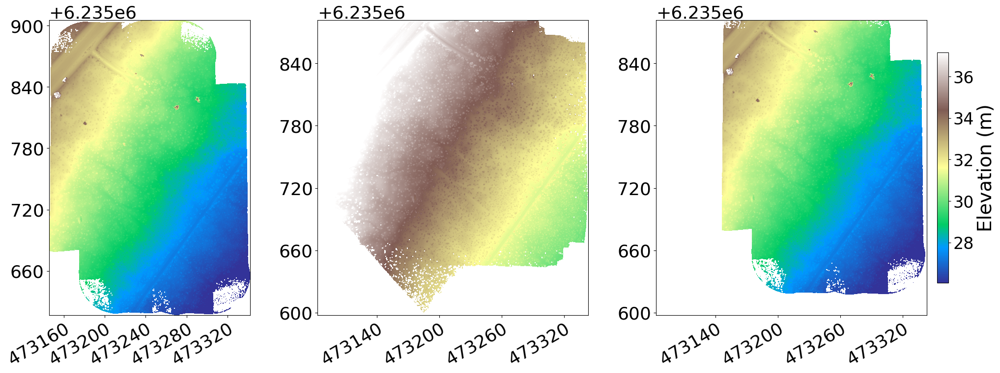

Saved: figures/dsm_grid_standardisation_before_gefolki.png


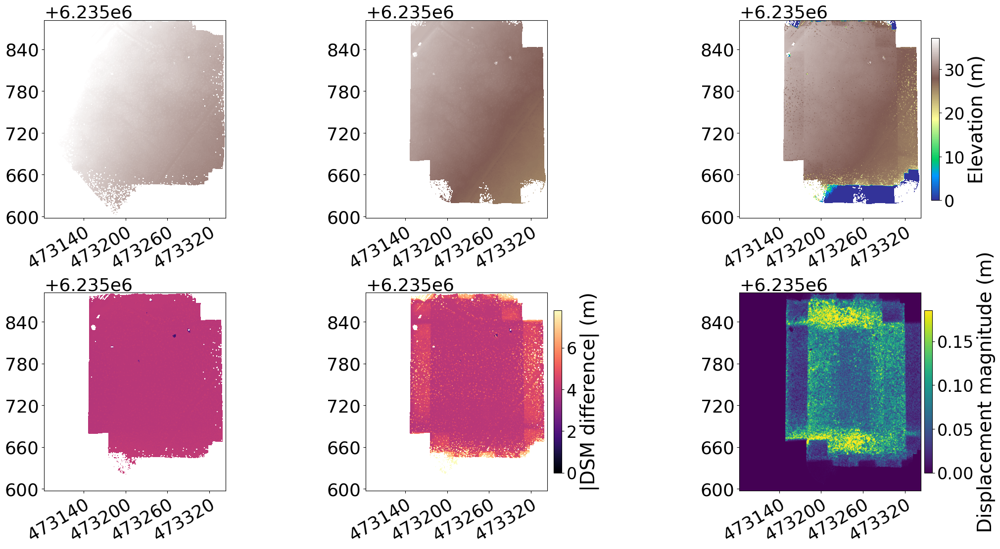

Saved: figures/gefolki_coregistration_before_after.png


In [6]:
from pathlib import Path

import numpy as np
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


# ---------------------------------------------------------------------
# File paths
# ---------------------------------------------------------------------
lidar_original = "/media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/lidar/dsm/SASMDD0011_l1_dsm_03.tif"
imagery_template = "/media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/imagery/dsm/SASMDD0011_dsm_pc_3cm.tif"
lidar_resampled = "/media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/lidar/dsm/crop_to_rgb/SASMDD0011_l1_dsm_03.tif"

# Optional explicit override. Leave as None to auto-resolve from common names.
lidar_corrected = None

# Optional explicit flow-field paths. Leave as None to auto-resolve common names.
flow_u_path = None
flow_v_path = None

FLOW_UNITS = "pixels"


# ---------------------------------------------------------------------
# Output and style settings
# ---------------------------------------------------------------------
out_dir = Path("figures")
out_dir.mkdir(parents=True, exist_ok=True)

MAX_DIM = 3000  # Downsample only for plotting large rasters.

TICK_SIZE = 26
CBAR_LABEL_SIZE = 28
CBAR_TICK_SIZE = 24
TEXT_SIZE = 26
X_TICK_ROTATION = 30

FIG1_SIZE = (22, 7.5)
FIG2_SIZE = (22, 11)

plt.rcParams.update({
    "font.size": TICK_SIZE,
    "axes.labelsize": TICK_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})


# ---------------------------------------------------------------------
# Helper functions
# ---------------------------------------------------------------------
def path_exists(path):
    return path is not None and Path(path).exists()


def first_existing(paths):
    for path in paths:
        if path is not None and Path(path).exists():
            return str(path)
    return None


def raster_extent_from_meta(meta):
    transform = meta["transform"]
    width = meta["width"]
    height = meta["height"]

    left = transform.c
    top = transform.f
    right = left + width * transform.a
    bottom = top + height * transform.e

    return (left, right, bottom, top)


def read_raster_for_plot(
    path,
    out_shape=None,
    max_dim=MAX_DIM,
    resampling=Resampling.bilinear,
):
    """
    Read a raster as a masked float32 array.

    Large rasters are downsampled for visualisation only.
    The original raster files are not modified.
    """
    path = Path(path)

    with rasterio.open(path) as src:
        if out_shape is None:
            if max(src.height, src.width) > max_dim:
                scale = max(src.height, src.width) / max_dim
                out_height = int(round(src.height / scale))
                out_width = int(round(src.width / scale))
                out_shape = (out_height, out_width)
            else:
                out_shape = (src.height, src.width)

        arr = src.read(
            1,
            masked=True,
            out_shape=out_shape,
            resampling=resampling,
        ).astype("float32")

        arr = np.ma.masked_invalid(arr)

        meta = {
            "height": src.height,
            "width": src.width,
            "transform": src.transform,
            "crs": src.crs,
            "res": src.res,
            "nodata": src.nodata,
        }

    return arr, meta


def robust_limits_from_arrays(arrays, pmin=2, pmax=98):
    vals = []

    for arr in arrays:
        if arr is None:
            continue

        if isinstance(arr, np.ma.MaskedArray):
            v = arr.compressed()
        else:
            v = np.asarray(arr).ravel()
            v = v[np.isfinite(v)]

        if v.size > 0:
            vals.append(v)

    if not vals:
        raise ValueError("No valid values available for percentile limits.")

    vals = np.concatenate(vals)
    return float(np.percentile(vals, pmin)), float(np.percentile(vals, pmax))


def robust_limits_from_paths(paths, pmin=2, pmax=98, max_dim=1500):
    arrays = []

    for path in paths:
        if path_exists(path):
            arr, _ = read_raster_for_plot(path, max_dim=max_dim)
            arrays.append(arr)

    return robust_limits_from_arrays(arrays, pmin=pmin, pmax=pmax)


def read_array_or_raster(path, out_shape=None):
    """
    Read a GeoTIFF, .npy, or .npz displacement field for plotting.
    """
    path = Path(path)
    suffix = path.suffix.lower()

    if suffix in [".tif", ".tiff"]:
        arr, _ = read_raster_for_plot(path, out_shape=out_shape)
        return arr

    if suffix == ".npy":
        arr = np.load(path).astype("float32")
        arr = np.ma.masked_invalid(arr)

    elif suffix == ".npz":
        npz = np.load(path)
        first_key = npz.files[0]
        arr = npz[first_key].astype("float32")
        arr = np.ma.masked_invalid(arr)

    else:
        raise ValueError(f"Unsupported flow-field format: {suffix}")

    if out_shape is not None and arr.shape != out_shape:
        sy = max(1, int(round(arr.shape[0] / out_shape[0])))
        sx = max(1, int(round(arr.shape[1] / out_shape[1])))
        arr = arr[::sy, ::sx]
        arr = arr[:out_shape[0], :out_shape[1]]

    return arr


def style_map_axis(
    ax,
    extent,
    tick_size=TICK_SIZE,
    nbins=5,
    x_rotation=X_TICK_ROTATION,
):
    """
    Apply consistent map-axis styling.
    """
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])

    ax.xaxis.set_major_locator(MaxNLocator(nbins=nbins))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=nbins))

    ax.tick_params(axis="both", labelsize=tick_size)

    for label in ax.get_xticklabels():
        label.set_rotation(x_rotation)
        label.set_ha("right")
        label.set_rotation_mode("anchor")
        label.set_fontsize(tick_size)

    for label in ax.get_yticklabels():
        label.set_fontsize(tick_size)


def style_colorbar(cbar, label):
    """
    Apply consistent colourbar styling.
    """
    cbar.set_label(label, fontsize=CBAR_LABEL_SIZE)
    cbar.ax.tick_params(labelsize=CBAR_TICK_SIZE)


# ---------------------------------------------------------------------
# Auto-resolve corrected DSM and flow fields
# ---------------------------------------------------------------------
lidar_resampled_path = Path(lidar_resampled)

stem = lidar_resampled_path.stem
crop_dir = lidar_resampled_path.parent
dsm_dir = crop_dir.parent
site_dir = dsm_dir.parent.parent
imagery_dsm_dir = Path(imagery_template).parent

if not path_exists(lidar_corrected):
    lidar_corrected = first_existing([
        crop_dir / f"{stem}_coreg.tif",
        crop_dir / f"{stem}_gefolki.tif",
        dsm_dir / "coregistered" / f"{stem}_coreg.tif",
        dsm_dir / "coregistered" / f"{stem}_gefolki.tif",
        dsm_dir / f"{stem}_coreg.tif",
        dsm_dir / f"{stem}_gefolki.tif",
    ])

if not path_exists(flow_u_path):
    flow_u_path = first_existing([
        imagery_dsm_dir / "flow_u_03_l1.npy",
        imagery_dsm_dir / "flow_u_03.npy",
        site_dir / "imagery" / "dsm" / "flow_u_03_l1.npy",
        site_dir / "imagery" / "dsm" / "flow_u_03.npy",
    ])

if not path_exists(flow_v_path):
    flow_v_path = first_existing([
        imagery_dsm_dir / "flow_v_03_l1.npy",
        imagery_dsm_dir / "flow_v_03.npy",
        site_dir / "imagery" / "dsm" / "flow_v_03_l1.npy",
        site_dir / "imagery" / "dsm" / "flow_v_03.npy",
    ])

print("lidar_corrected:", lidar_corrected)
print("flow_u_path:", flow_u_path)
print("flow_v_path:", flow_v_path)


# ---------------------------------------------------------------------
# Figure 1: DSM grid standardisation / resampling
# ---------------------------------------------------------------------
vmin, vmax = robust_limits_from_paths(
    [lidar_original, imagery_template, lidar_resampled],
    pmin=2,
    pmax=98,
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=FIG1_SIZE,
    constrained_layout=True,
)

panels = [
    lidar_original,
    imagery_template,
    lidar_resampled,
]

last_im = None

for ax, path in zip(axes, panels):
    arr, meta = read_raster_for_plot(path)
    extent = raster_extent_from_meta(meta)

    last_im = ax.imshow(
        arr,
        cmap="terrain",
        vmin=vmin,
        vmax=vmax,
        extent=extent,
        origin="upper",
    )

    style_map_axis(
        ax,
        extent,
        tick_size=TICK_SIZE,
        nbins=5,
        x_rotation=X_TICK_ROTATION,
    )

cbar = fig.colorbar(
    last_im,
    ax=axes.ravel().tolist(),
    shrink=0.78,
    pad=0.01,
)

style_colorbar(cbar, "Elevation (m)")

fig_path = out_dir / "dsm_grid_standardisation_before_gefolki.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {fig_path}")


# ---------------------------------------------------------------------
# Figure 2: GeFolki/eFOLKI co-registration evidence
# ---------------------------------------------------------------------
if path_exists(lidar_corrected):
    with rasterio.open(imagery_template) as src:
        if max(src.height, src.width) > MAX_DIM:
            scale = max(src.height, src.width) / MAX_DIM
            out_shape = (
                int(round(src.height / scale)),
                int(round(src.width / scale)),
            )
        else:
            out_shape = (src.height, src.width)

        pixel_width = abs(src.transform.a)
        pixel_height = abs(src.transform.e)

    template, template_meta = read_raster_for_plot(
        imagery_template,
        out_shape=out_shape,
    )

    before, _ = read_raster_for_plot(
        lidar_resampled,
        out_shape=out_shape,
    )

    after, _ = read_raster_for_plot(
        lidar_corrected,
        out_shape=out_shape,
    )

    plot_extent = raster_extent_from_meta(template_meta)

    elev_vmin, elev_vmax = robust_limits_from_arrays(
        [template, before, after],
        pmin=2,
        pmax=98,
    )

    residual_before = np.ma.abs(before - template)
    residual_after = np.ma.abs(after - template)

    _, residual_vmax = robust_limits_from_arrays(
        [residual_before, residual_after],
        pmin=2,
        pmax=98,
    )

    has_flow = path_exists(flow_u_path) and path_exists(flow_v_path)

    if has_flow:
        u = read_array_or_raster(flow_u_path, out_shape=out_shape)
        v = read_array_or_raster(flow_v_path, out_shape=out_shape)

        if FLOW_UNITS.lower() == "pixels":
            displacement = np.ma.sqrt(
                (u * pixel_width) ** 2 + (v * pixel_height) ** 2
            )
            displacement_label = "Displacement magnitude (m)"
        else:
            displacement = np.ma.sqrt(u**2 + v**2)
            displacement_label = "Displacement magnitude (m)"

        _, displacement_vmax = robust_limits_from_arrays(
            [displacement],
            pmin=2,
            pmax=98,
        )
    else:
        displacement = None
        displacement_vmax = None
        displacement_label = "Displacement magnitude"

    fig, axes = plt.subplots(
        2,
        3,
        figsize=FIG2_SIZE,
        constrained_layout=True,
    )

    # Top row: DSM surfaces
    elevation_panels = [
        template,
        before,
        after,
    ]

    im_elev = None

    for ax, arr in zip(axes[0, :], elevation_panels):
        im_elev = ax.imshow(
            arr,
            cmap="terrain",
            vmin=elev_vmin,
            vmax=elev_vmax,
            extent=plot_extent,
            origin="upper",
        )

        style_map_axis(
            ax,
            plot_extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

    cbar_elev = fig.colorbar(
        im_elev,
        ax=axes[0, :].ravel().tolist(),
        shrink=0.82,
        pad=0.01,
    )

    style_colorbar(cbar_elev, "Elevation (m)")

    # Bottom row: residuals and displacement magnitude
    residual_panels = [
        residual_before,
        residual_after,
    ]

    im_res = None

    for ax, arr in zip(axes[1, 0:2], residual_panels):
        im_res = ax.imshow(
            arr,
            cmap="magma",
            vmin=0,
            vmax=residual_vmax,
            extent=plot_extent,
            origin="upper",
        )

        style_map_axis(
            ax,
            plot_extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

    cbar_res = fig.colorbar(
        im_res,
        ax=axes[1, 0:2].ravel().tolist(),
        shrink=0.82,
        pad=0.01,
    )

    style_colorbar(cbar_res, "|DSM difference| (m)")

    if has_flow:
        im_disp = axes[1, 2].imshow(
            displacement,
            cmap="viridis",
            vmin=0,
            vmax=displacement_vmax,
            extent=plot_extent,
            origin="upper",
        )

        style_map_axis(
            axes[1, 2],
            plot_extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

        cbar_disp = fig.colorbar(
            im_disp,
            ax=axes[1, 2],
            shrink=0.82,
            pad=0.01,
        )

        style_colorbar(cbar_disp, displacement_label)

    else:
        axes[1, 2].text(
            0.5,
            0.5,
            "Flow fields not provided",
            ha="center",
            va="center",
            transform=axes[1, 2].transAxes,
            fontsize=TEXT_SIZE,
        )

        style_map_axis(
            axes[1, 2],
            plot_extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

    fig_path = out_dir / "gefolki_coregistration_before_after.png"
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Saved: {fig_path}")

else:
    tried_corrected = [
        crop_dir / f"{stem}_coreg.tif",
        crop_dir / f"{stem}_gefolki.tif",
        dsm_dir / "coregistered" / f"{stem}_coreg.tif",
        dsm_dir / "coregistered" / f"{stem}_gefolki.tif",
        dsm_dir / f"{stem}_coreg.tif",
        dsm_dir / f"{stem}_gefolki.tif",
    ]

    print("Skipped GeFolki/eFOLKI result figure because no corrected LiDAR DSM was found.")
    print("Checked:")

    for path in tried_corrected:
        print(f"  - {path}")

In [7]:
# ---------------------------------------------------------------------
# Simple flow-field statistics
# ---------------------------------------------------------------------
def summarise_flow(displacement, u=None, v=None, pixel_width=None, pixel_height=None, flow_units="pixels"):
    """
    Summarise horizontal displacement magnitude.
    If u and v are provided, also summarise signed dx and dy.
    """

    if isinstance(displacement, np.ma.MaskedArray):
        d = displacement.compressed()
    else:
        d = np.asarray(displacement).ravel()
        d = d[np.isfinite(d)]

    stats = {
        "mean_m": np.mean(d),
        "median_m": np.median(d),
        "p85_m": np.percentile(d, 85),
        "p95_m": np.percentile(d, 95),
        "max_m": np.max(d),
    }

    print("\nFlow displacement magnitude")
    print(f"Mean:   {stats['mean_m']:.4f} m ({stats['mean_m'] * 100:.1f} cm)")
    print(f"Median: {stats['median_m']:.4f} m ({stats['median_m'] * 100:.1f} cm)")
    print(f"P85:    {stats['p85_m']:.4f} m ({stats['p85_m'] * 100:.1f} cm)")
    print(f"P95:    {stats['p95_m']:.4f} m ({stats['p95_m'] * 100:.1f} cm)")
    print(f"Max:    {stats['max_m']:.4f} m ({stats['max_m'] * 100:.1f} cm)")

    if u is not None and v is not None and pixel_width is not None and pixel_height is not None:
        if flow_units.lower() == "pixels":
            dx = u * pixel_width
            dy = v * pixel_height
        else:
            dx = u
            dy = v

        if isinstance(dx, np.ma.MaskedArray):
            dx_vals = dx.compressed()
            dy_vals = dy.compressed()
        else:
            dx_vals = np.asarray(dx).ravel()
            dy_vals = np.asarray(dy).ravel()
            valid = np.isfinite(dx_vals) & np.isfinite(dy_vals)
            dx_vals = dx_vals[valid]
            dy_vals = dy_vals[valid]

        print("\nSigned flow components")
        print(f"Mean ΔX: {np.mean(dx_vals):.4f} m ({np.mean(dx_vals) * 100:.1f} cm)")
        print(f"Mean ΔY: {np.mean(dy_vals):.4f} m ({np.mean(dy_vals) * 100:.1f} cm)")

        stats["mean_dx_m"] = np.mean(dx_vals)
        stats["mean_dy_m"] = np.mean(dy_vals)

    return stats


flow_stats = summarise_flow(
    displacement,
    u=u if has_flow else None,
    v=v if has_flow else None,
    pixel_width=pixel_width if has_flow else None,
    pixel_height=pixel_height if has_flow else None,
    flow_units=FLOW_UNITS,
)


Flow displacement magnitude
Mean:   0.0455 m (4.6 cm)
Median: 0.0237 m (2.4 cm)
P85:    0.1087 m (10.9 cm)
P95:    0.1548 m (15.5 cm)
Max:    0.3856 m (38.6 cm)

Signed flow components
Mean ΔX: 0.0006 m (0.1 cm)
Mean ΔY: 0.0019 m (0.2 cm)



Low-density site
lidar_corrected: /media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/lidar/dsm/crop_to_rgb/SASMDD0011_l1_dsm_03_coreg.tif
flow_u_path: /media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/imagery/dsm/flow_u_03_l1.npy
flow_v_path: /media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/imagery/dsm/flow_v_03_l1.npy


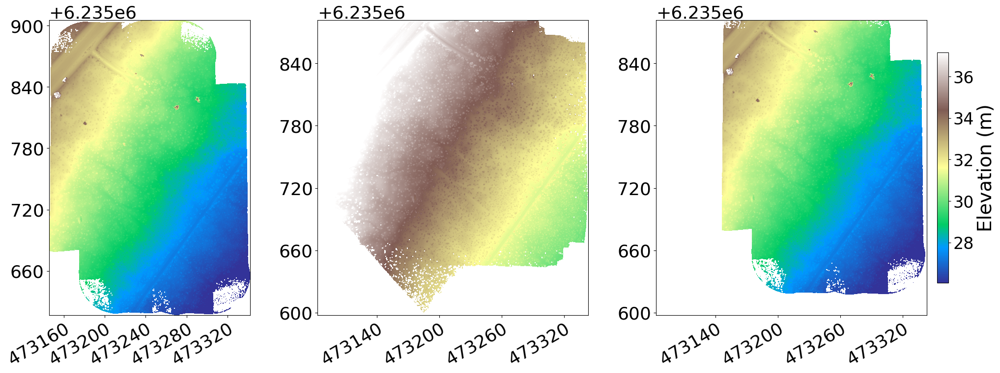

Saved: figures_coregistration/low_density_dsm_grid_standardisation_before_gefolki.png

Flow displacement statistics: Low-density site
Mean:    0.0419 m (4.2 cm)
Median:  0.0162 m (1.6 cm)
P85:     0.1036 m (10.4 cm)
P95:     0.1510 m (15.1 cm)
Max:     0.3813 m (38.1 cm)
Mean ΔX: 0.0007 m (0.1 cm)
Mean ΔY: 0.0017 m (0.2 cm)


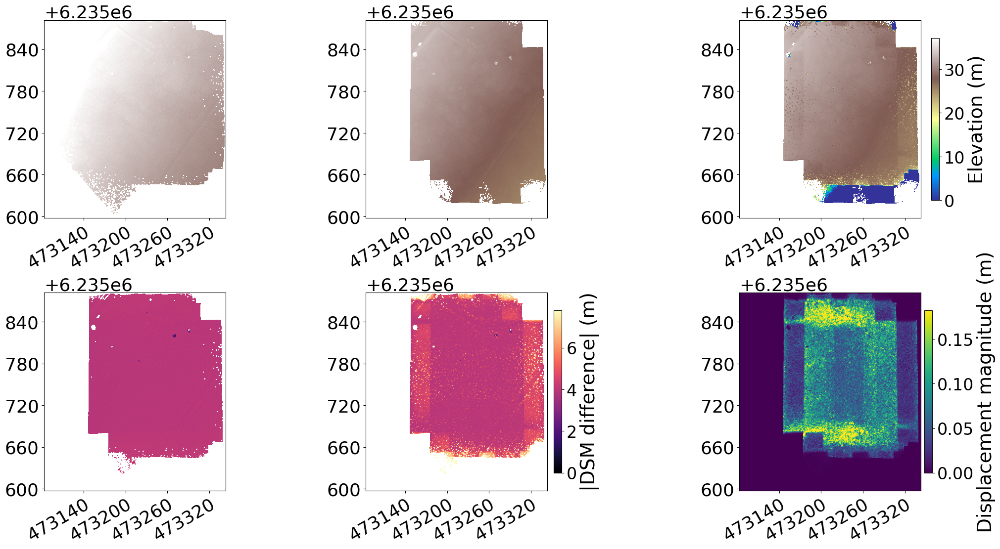

Saved: figures_coregistration/low_density_gefolki_coregistration_before_after.png

Medium-density site
lidar_corrected: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg.tif
flow_u_path: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/dsm/flow_u_03_l1.npy
flow_v_path: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/dsm/flow_v_03_l1.npy


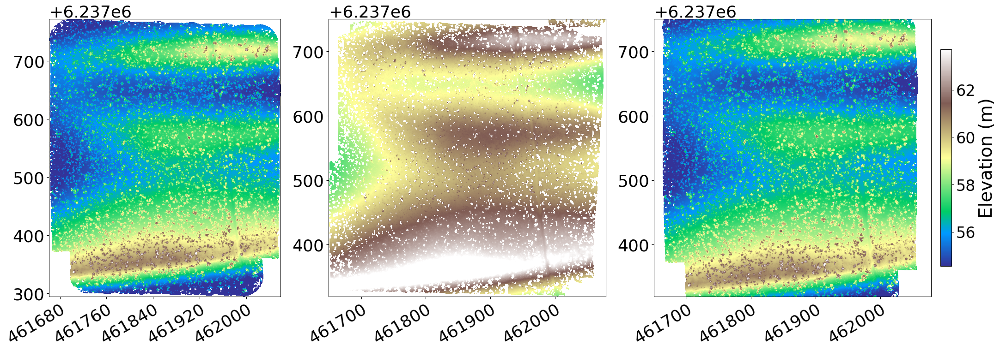

Saved: figures_coregistration/medium_density_dsm_grid_standardisation_before_gefolki.png

Flow displacement statistics: Medium-density site
Mean:    0.0736 m (7.4 cm)
Median:  0.0551 m (5.5 cm)
P85:     0.1522 m (15.2 cm)
P95:     0.2227 m (22.3 cm)
Max:     0.4904 m (49.0 cm)
Mean ΔX: 0.0041 m (0.4 cm)
Mean ΔY: 0.0060 m (0.6 cm)


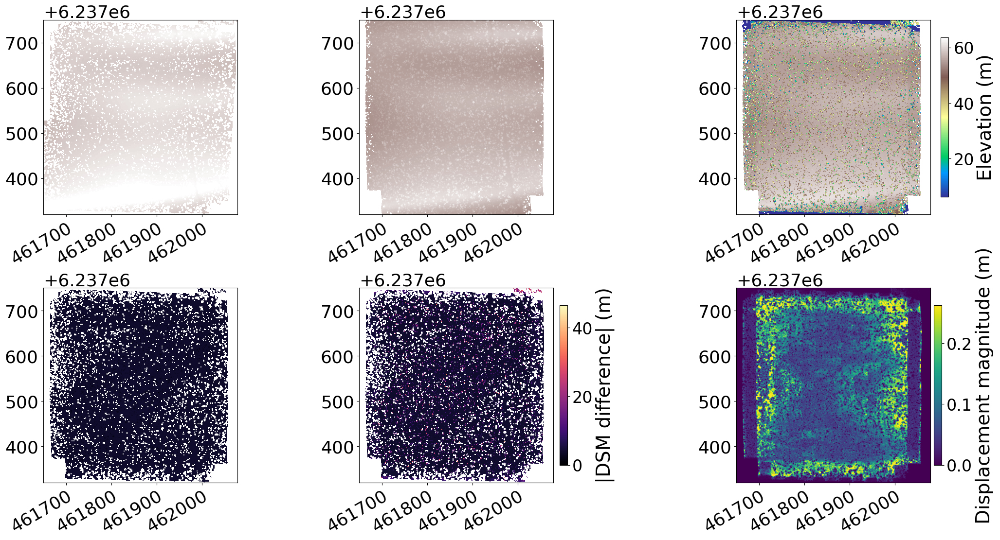

Saved: figures_coregistration/medium_density_gefolki_coregistration_before_after.png

Saved flow statistics: figures_coregistration/flow_displacement_statistics.csv

LaTeX table rows:
Low-density site & 0.0419 & 0.0162 & 0.1036 & 0.1510 & 0.3813 & 0.0007 & 0.0017 \\
Medium-density site & 0.0736 & 0.0551 & 0.1522 & 0.2227 & 0.4904 & 0.0041 & 0.0060 \\


In [8]:
from pathlib import Path
import csv

import numpy as np
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


# ---------------------------------------------------------------------
# Site configuration
# ---------------------------------------------------------------------
SITES = [
    {
        "site_key": "low_density",
        "site_label": "Low-density site",
        "lidar_original": "/media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/lidar/dsm/SASMDD0011_l1_dsm_03.tif",
        "imagery_template": "/media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/imagery/dsm/SASMDD0011_dsm_pc_3cm.tif",
        "lidar_resampled": "/media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/lidar/dsm/crop_to_rgb/SASMDD0011_l1_dsm_03.tif",
        "lidar_corrected": None,
        "flow_u_path": None,
        "flow_v_path": None,
    },
    {
        "site_key": "medium_density",
        "site_label": "Medium-density site",
        "lidar_original": "/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif",
        "imagery_template": "/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif",
        "lidar_resampled": "/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif",
        "lidar_corrected": None,
        "flow_u_path": None,
        "flow_v_path": None,
    },
]


# ---------------------------------------------------------------------
# Output and style settings
# ---------------------------------------------------------------------
OUT_DIR = Path("figures_coregistration")
OUT_DIR.mkdir(parents=True, exist_ok=True)

FLOW_UNITS = "pixels"

MAX_DIM = 3000
SAVE_DPI = 300

TICK_SIZE = 26
CBAR_LABEL_SIZE = 28
CBAR_TICK_SIZE = 24
TEXT_SIZE = 26
X_TICK_ROTATION = 30

FIG_GRID_SIZE = (22, 7.5)
FIG_COREG_SIZE = (22, 11)

plt.rcParams.update({
    "font.size": TICK_SIZE,
    "axes.labelsize": TICK_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})


# ---------------------------------------------------------------------
# Helper functions
# ---------------------------------------------------------------------
def path_exists(path):
    return path is not None and Path(path).exists()


def first_existing(paths):
    for path in paths:
        if path is not None and Path(path).exists():
            return str(path)
    return None


def raster_extent_from_meta(meta):
    transform = meta["transform"]
    width = meta["width"]
    height = meta["height"]

    left = transform.c
    top = transform.f
    right = left + width * transform.a
    bottom = top + height * transform.e

    return left, right, bottom, top


def read_raster_for_plot(
    path,
    out_shape=None,
    max_dim=MAX_DIM,
    resampling=Resampling.bilinear,
):
    """
    Read a raster as a masked float32 array.
    Large rasters are downsampled for plotting only.
    """
    path = Path(path)

    with rasterio.open(path) as src:
        if out_shape is None:
            if max(src.height, src.width) > max_dim:
                scale = max(src.height, src.width) / max_dim
                out_height = int(round(src.height / scale))
                out_width = int(round(src.width / scale))
                out_shape = (out_height, out_width)
            else:
                out_shape = (src.height, src.width)

        arr = src.read(
            1,
            masked=True,
            out_shape=out_shape,
            resampling=resampling,
        ).astype("float32")

        arr = np.ma.masked_invalid(arr)

        meta = {
            "height": src.height,
            "width": src.width,
            "transform": src.transform,
            "crs": src.crs,
            "res": src.res,
            "nodata": src.nodata,
        }

    return arr, meta


def robust_limits_from_arrays(arrays, pmin=2, pmax=98):
    vals = []

    for arr in arrays:
        if arr is None:
            continue

        if isinstance(arr, np.ma.MaskedArray):
            v = arr.compressed()
        else:
            v = np.asarray(arr).ravel()
            v = v[np.isfinite(v)]

        if v.size > 0:
            vals.append(v)

    if not vals:
        raise ValueError("No valid values available for colour limits.")

    vals = np.concatenate(vals)
    return float(np.percentile(vals, pmin)), float(np.percentile(vals, pmax))


def robust_limits_from_paths(paths, pmin=2, pmax=98, max_dim=1500):
    arrays = []

    for path in paths:
        if path_exists(path):
            arr, _ = read_raster_for_plot(path, max_dim=max_dim)
            arrays.append(arr)

    return robust_limits_from_arrays(arrays, pmin=pmin, pmax=pmax)


def resize_array_to_shape(arr, out_shape):
    """
    Resize by index sampling for plotting/statistics.
    This avoids adding another dependency.
    """
    if out_shape is None or arr.shape == out_shape:
        return arr

    row_idx = np.linspace(0, arr.shape[0] - 1, out_shape[0]).astype(int)
    col_idx = np.linspace(0, arr.shape[1] - 1, out_shape[1]).astype(int)

    return arr[np.ix_(row_idx, col_idx)]


def read_array_or_raster(path, out_shape=None):
    """
    Read a GeoTIFF, .npy, or .npz displacement field.
    """
    path = Path(path)
    suffix = path.suffix.lower()

    if suffix in [".tif", ".tiff"]:
        arr, _ = read_raster_for_plot(path, out_shape=out_shape)
        return arr

    if suffix == ".npy":
        arr = np.load(path).astype("float32")
        arr = np.ma.masked_invalid(arr)

    elif suffix == ".npz":
        npz = np.load(path)
        first_key = npz.files[0]
        arr = npz[first_key].astype("float32")
        arr = np.ma.masked_invalid(arr)

    else:
        raise ValueError(f"Unsupported flow-field format: {suffix}")

    arr = resize_array_to_shape(arr, out_shape)
    return arr


def style_map_axis(
    ax,
    extent,
    tick_size=TICK_SIZE,
    nbins=5,
    x_rotation=X_TICK_ROTATION,
):
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])

    ax.xaxis.set_major_locator(MaxNLocator(nbins=nbins))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=nbins))

    ax.tick_params(axis="both", labelsize=tick_size)

    for label in ax.get_xticklabels():
        label.set_rotation(x_rotation)
        label.set_ha("right")
        label.set_rotation_mode("anchor")
        label.set_fontsize(tick_size)

    for label in ax.get_yticklabels():
        label.set_fontsize(tick_size)


def style_colorbar(cbar, label):
    cbar.set_label(label, fontsize=CBAR_LABEL_SIZE)
    cbar.ax.tick_params(labelsize=CBAR_TICK_SIZE)


def resolve_coreg_paths(site):
    """
    Auto-resolve corrected DSM and flow fields using common filenames.
    Explicit paths in SITES take priority.
    """
    site = site.copy()

    lidar_resampled_path = Path(site["lidar_resampled"])

    stem = lidar_resampled_path.stem
    crop_dir = lidar_resampled_path.parent
    dsm_dir = crop_dir.parent
    site_dir = dsm_dir.parent.parent
    imagery_dsm_dir = Path(site["imagery_template"]).parent

    if not path_exists(site.get("lidar_corrected")):
        site["lidar_corrected"] = first_existing([
            crop_dir / f"{stem}_coreg.tif",
            crop_dir / f"{stem}_gefolki.tif",
            dsm_dir / "coregistered" / f"{stem}_coreg.tif",
            dsm_dir / "coregistered" / f"{stem}_gefolki.tif",
            dsm_dir / f"{stem}_coreg.tif",
            dsm_dir / f"{stem}_gefolki.tif",
        ])

    if not path_exists(site.get("flow_u_path")):
        site["flow_u_path"] = first_existing([
            imagery_dsm_dir / "flow_u_03_l1.npy",
            imagery_dsm_dir / "flow_u_03.npy",
            imagery_dsm_dir / "flow_u.npy",
            site_dir / "imagery" / "dsm" / "flow_u_03_l1.npy",
            site_dir / "imagery" / "dsm" / "flow_u_03.npy",
            site_dir / "imagery" / "dsm" / "flow_u.npy",
        ])

    if not path_exists(site.get("flow_v_path")):
        site["flow_v_path"] = first_existing([
            imagery_dsm_dir / "flow_v_03_l1.npy",
            imagery_dsm_dir / "flow_v_03.npy",
            imagery_dsm_dir / "flow_v.npy",
            site_dir / "imagery" / "dsm" / "flow_v_03_l1.npy",
            site_dir / "imagery" / "dsm" / "flow_v_03.npy",
            site_dir / "imagery" / "dsm" / "flow_v.npy",
        ])

    return site


def summarise_displacement(site_label, displacement, u, v, pixel_width, pixel_height):
    """
    Summarise dense horizontal displacement field in metres.
    """
    if isinstance(displacement, np.ma.MaskedArray):
        d = displacement.compressed()
    else:
        d = np.asarray(displacement).ravel()
        d = d[np.isfinite(d)]

    if FLOW_UNITS.lower() == "pixels":
        dx = u * pixel_width
        dy = v * pixel_height
    else:
        dx = u
        dy = v

    dx = np.ma.masked_invalid(dx)
    dy = np.ma.masked_invalid(dy)

    combined_mask = np.ma.getmaskarray(dx) | np.ma.getmaskarray(dy)
    dx_vals = np.ma.array(dx, mask=combined_mask).compressed()
    dy_vals = np.ma.array(dy, mask=combined_mask).compressed()

    stats = {
        "site": site_label,
        "mean_m": float(np.mean(d)),
        "median_m": float(np.median(d)),
        "p85_m": float(np.percentile(d, 85)),
        "p95_m": float(np.percentile(d, 95)),
        "max_m": float(np.max(d)),
        "mean_dx_m": float(np.mean(dx_vals)),
        "mean_dy_m": float(np.mean(dy_vals)),
    }

    print(f"\nFlow displacement statistics: {site_label}")
    print(f"Mean:    {stats['mean_m']:.4f} m ({stats['mean_m'] * 100:.1f} cm)")
    print(f"Median:  {stats['median_m']:.4f} m ({stats['median_m'] * 100:.1f} cm)")
    print(f"P85:     {stats['p85_m']:.4f} m ({stats['p85_m'] * 100:.1f} cm)")
    print(f"P95:     {stats['p95_m']:.4f} m ({stats['p95_m'] * 100:.1f} cm)")
    print(f"Max:     {stats['max_m']:.4f} m ({stats['max_m'] * 100:.1f} cm)")
    print(f"Mean ΔX: {stats['mean_dx_m']:.4f} m ({stats['mean_dx_m'] * 100:.1f} cm)")
    print(f"Mean ΔY: {stats['mean_dy_m']:.4f} m ({stats['mean_dy_m'] * 100:.1f} cm)")

    return stats


# ---------------------------------------------------------------------
# Figure 1: DSM grid standardisation
# ---------------------------------------------------------------------
def plot_grid_standardisation(site):
    vmin, vmax = robust_limits_from_paths(
        [
            site["lidar_original"],
            site["imagery_template"],
            site["lidar_resampled"],
        ],
        pmin=2,
        pmax=98,
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=FIG_GRID_SIZE,
        constrained_layout=True,
    )

    panels = [
        site["lidar_original"],
        site["imagery_template"],
        site["lidar_resampled"],
    ]

    last_im = None

    for ax, path in zip(axes, panels):
        arr, meta = read_raster_for_plot(path)
        extent = raster_extent_from_meta(meta)

        last_im = ax.imshow(
            arr,
            cmap="terrain",
            vmin=vmin,
            vmax=vmax,
            extent=extent,
            origin="upper",
        )

        style_map_axis(
            ax,
            extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

    cbar = fig.colorbar(
        last_im,
        ax=axes.ravel().tolist(),
        shrink=0.78,
        pad=0.01,
    )
    style_colorbar(cbar, "Elevation (m)")

    fig_path = OUT_DIR / f"{site['site_key']}_dsm_grid_standardisation_before_gefolki.png"
    fig.savefig(fig_path, dpi=SAVE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {fig_path}")
    return fig_path


# ---------------------------------------------------------------------
# Figure 2: eFOLKI co-registration diagnostics
# ---------------------------------------------------------------------
def plot_coregistration_diagnostics(site):
    if not path_exists(site["lidar_corrected"]):
        print(f"\nSkipped {site['site_label']}: corrected LiDAR DSM not found.")
        print("Set 'lidar_corrected' manually in SITES if the filename differs.")
        return None, None

    with rasterio.open(site["imagery_template"]) as src:
        if max(src.height, src.width) > MAX_DIM:
            scale = max(src.height, src.width) / MAX_DIM
            out_shape = (
                int(round(src.height / scale)),
                int(round(src.width / scale)),
            )
        else:
            out_shape = (src.height, src.width)

        pixel_width = abs(src.transform.a)
        pixel_height = abs(src.transform.e)

    template, template_meta = read_raster_for_plot(
        site["imagery_template"],
        out_shape=out_shape,
    )
    before, _ = read_raster_for_plot(
        site["lidar_resampled"],
        out_shape=out_shape,
    )
    after, _ = read_raster_for_plot(
        site["lidar_corrected"],
        out_shape=out_shape,
    )

    plot_extent = raster_extent_from_meta(template_meta)

    elev_vmin, elev_vmax = robust_limits_from_arrays(
        [template, before, after],
        pmin=2,
        pmax=98,
    )

    residual_before = np.ma.abs(before - template)
    residual_after = np.ma.abs(after - template)

    _, residual_vmax = robust_limits_from_arrays(
        [residual_before, residual_after],
        pmin=2,
        pmax=98,
    )

    has_flow = path_exists(site["flow_u_path"]) and path_exists(site["flow_v_path"])

    displacement = None
    displacement_vmax = None
    displacement_label = "Displacement magnitude (m)"
    flow_stats = None

    if has_flow:
        u = read_array_or_raster(site["flow_u_path"], out_shape=out_shape)
        v = read_array_or_raster(site["flow_v_path"], out_shape=out_shape)

        if FLOW_UNITS.lower() == "pixels":
            displacement = np.ma.sqrt(
                (u * pixel_width) ** 2 + (v * pixel_height) ** 2
            )
        else:
            displacement = np.ma.sqrt(u**2 + v**2)

        _, displacement_vmax = robust_limits_from_arrays(
            [displacement],
            pmin=2,
            pmax=98,
        )

        flow_stats = summarise_displacement(
            site["site_label"],
            displacement,
            u,
            v,
            pixel_width,
            pixel_height,
        )

    fig, axes = plt.subplots(
        2,
        3,
        figsize=FIG_COREG_SIZE,
        constrained_layout=True,
    )

    # Top row: RGB/SfM DSM, LiDAR before correction, LiDAR after correction.
    top_panels = [template, before, after]

    im_elev = None
    for ax, arr in zip(axes[0, :], top_panels):
        im_elev = ax.imshow(
            arr,
            cmap="terrain",
            vmin=elev_vmin,
            vmax=elev_vmax,
            extent=plot_extent,
            origin="upper",
        )

        style_map_axis(
            ax,
            plot_extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

    cbar_elev = fig.colorbar(
        im_elev,
        ax=axes[0, :].ravel().tolist(),
        shrink=0.82,
        pad=0.01,
    )
    style_colorbar(cbar_elev, "Elevation (m)")

    # Bottom row: residuals before/after and displacement magnitude.
    residual_panels = [residual_before, residual_after]

    im_res = None
    for ax, arr in zip(axes[1, 0:2], residual_panels):
        im_res = ax.imshow(
            arr,
            cmap="magma",
            vmin=0,
            vmax=residual_vmax,
            extent=plot_extent,
            origin="upper",
        )

        style_map_axis(
            ax,
            plot_extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

    cbar_res = fig.colorbar(
        im_res,
        ax=axes[1, 0:2].ravel().tolist(),
        shrink=0.82,
        pad=0.01,
    )
    style_colorbar(cbar_res, "|DSM difference| (m)")

    if has_flow:
        im_disp = axes[1, 2].imshow(
            displacement,
            cmap="viridis",
            vmin=0,
            vmax=displacement_vmax,
            extent=plot_extent,
            origin="upper",
        )

        style_map_axis(
            axes[1, 2],
            plot_extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

        cbar_disp = fig.colorbar(
            im_disp,
            ax=axes[1, 2],
            shrink=0.82,
            pad=0.01,
        )
        style_colorbar(cbar_disp, displacement_label)

    else:
        axes[1, 2].text(
            0.5,
            0.5,
            "Flow fields not provided",
            ha="center",
            va="center",
            transform=axes[1, 2].transAxes,
            fontsize=TEXT_SIZE,
        )

        style_map_axis(
            axes[1, 2],
            plot_extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

    fig_path = OUT_DIR / f"{site['site_key']}_gefolki_coregistration_before_after.png"
    fig.savefig(fig_path, dpi=SAVE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {fig_path}")
    return fig_path, flow_stats


# ---------------------------------------------------------------------
# Run both sites
# ---------------------------------------------------------------------
all_flow_stats = []

for site_cfg in SITES:
    site = resolve_coreg_paths(site_cfg)

    print("\n" + "=" * 80)
    print(site["site_label"])
    print("=" * 80)
    print("lidar_corrected:", site["lidar_corrected"])
    print("flow_u_path:", site["flow_u_path"])
    print("flow_v_path:", site["flow_v_path"])

    plot_grid_standardisation(site)
    _, stats = plot_coregistration_diagnostics(site)

    if stats is not None:
        all_flow_stats.append(stats)


# ---------------------------------------------------------------------
# Save flow statistics table
# ---------------------------------------------------------------------
if all_flow_stats:
    stats_path = OUT_DIR / "flow_displacement_statistics.csv"

    with open(stats_path, "w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=[
                "site",
                "mean_m",
                "median_m",
                "p85_m",
                "p95_m",
                "max_m",
                "mean_dx_m",
                "mean_dy_m",
            ],
        )
        writer.writeheader()
        writer.writerows(all_flow_stats)

    print(f"\nSaved flow statistics: {stats_path}")

    print("\nLaTeX table rows:")
    for s in all_flow_stats:
        print(
            f"{s['site']} & "
            f"{s['mean_m']:.4f} & "
            f"{s['median_m']:.4f} & "
            f"{s['p85_m']:.4f} & "
            f"{s['p95_m']:.4f} & "
            f"{s['max_m']:.4f} & "
            f"{s['mean_dx_m']:.4f} & "
            f"{s['mean_dy_m']:.4f} \\\\"
        )


Low-density site
lidar_corrected: /media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/lidar/dsm/crop_to_rgb/SASMDD0011_l1_dsm_03_coreg.tif
flow_u_path: /media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/imagery/dsm/flow_u_03_l1.npy
flow_v_path: /media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/imagery/dsm/flow_v_03_l1.npy


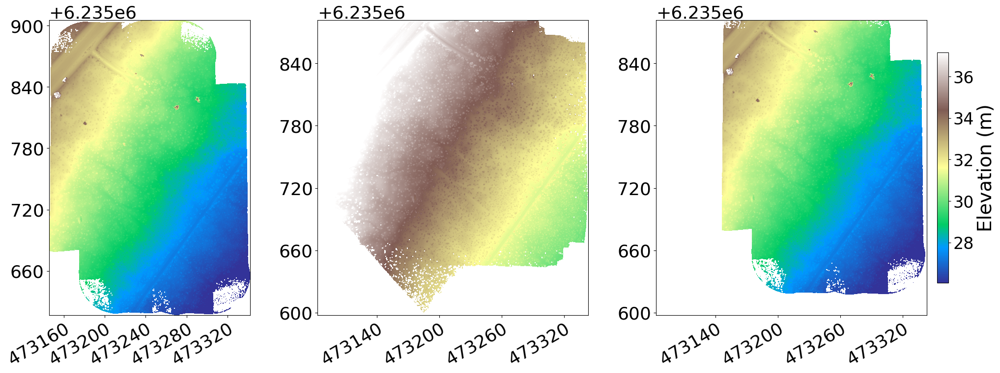

Saved: figures_coregistration/low_density_dsm_grid_standardisation_before_gefolki.png

Flow displacement statistics: Low-density site
Mean:    0.0419 m (4.2 cm)
Median:  0.0162 m (1.6 cm)
P85:     0.1036 m (10.4 cm)
P95:     0.1510 m (15.1 cm)
Max:     0.3813 m (38.1 cm)
Mean ΔX: 0.0007 m (0.1 cm)
Mean ΔY: 0.0017 m (0.2 cm)


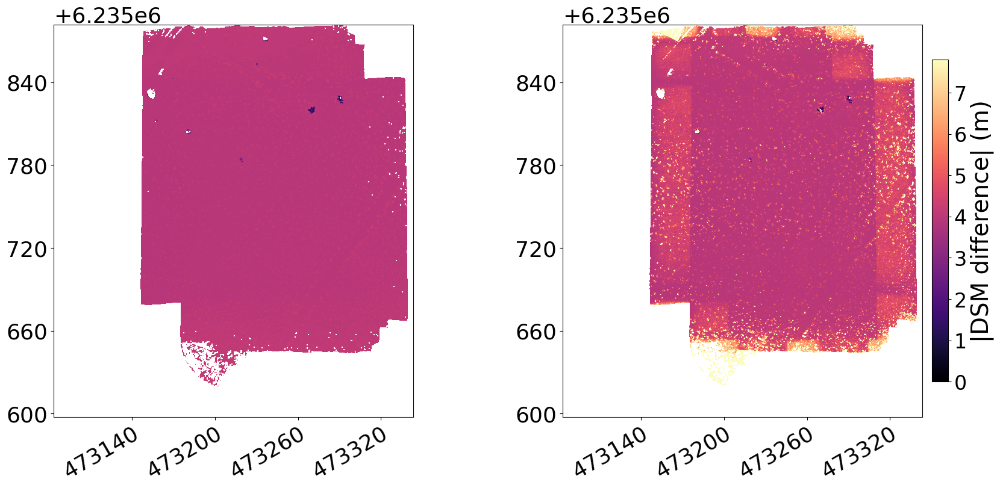

Saved: figures_coregistration/low_density_gefolki_coregistration_before_after.png

Medium-density site
lidar_corrected: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg.tif
flow_u_path: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/dsm/flow_u_03_l1.npy
flow_v_path: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/dsm/flow_v_03_l1.npy


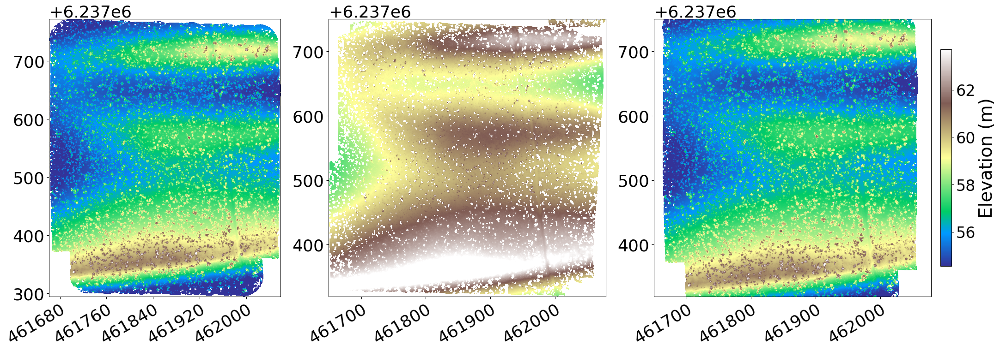

Saved: figures_coregistration/medium_density_dsm_grid_standardisation_before_gefolki.png

Flow displacement statistics: Medium-density site
Mean:    0.0736 m (7.4 cm)
Median:  0.0551 m (5.5 cm)
P85:     0.1522 m (15.2 cm)
P95:     0.2227 m (22.3 cm)
Max:     0.4904 m (49.0 cm)
Mean ΔX: 0.0041 m (0.4 cm)
Mean ΔY: 0.0060 m (0.6 cm)


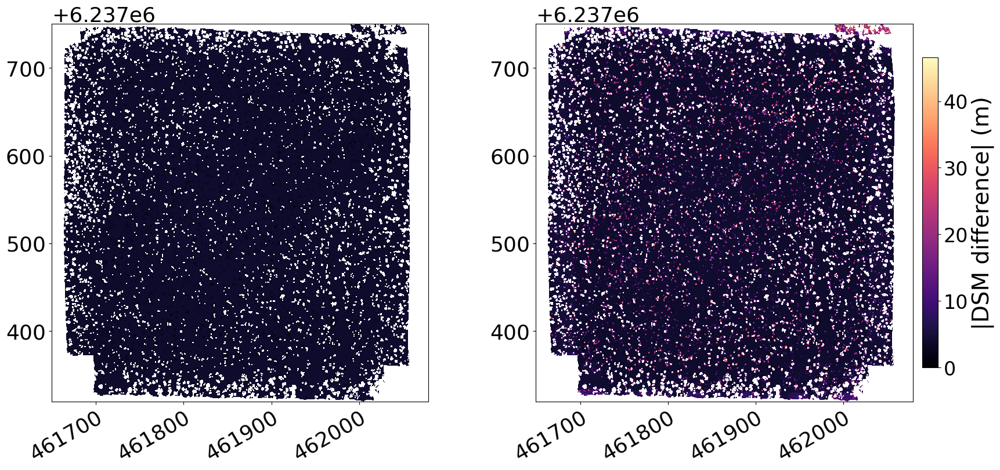

Saved: figures_coregistration/medium_density_gefolki_coregistration_before_after.png

Saved flow statistics: figures_coregistration/flow_displacement_statistics.csv

LaTeX table rows:
Low-density site & 0.0419 & 0.0162 & 0.1036 & 0.1510 & 0.3813 & 0.0007 & 0.0017 \\
Medium-density site & 0.0736 & 0.0551 & 0.1522 & 0.2227 & 0.4904 & 0.0041 & 0.0060 \\


In [10]:
from pathlib import Path
import csv

import numpy as np
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


# ---------------------------------------------------------------------
# Site configuration
# ---------------------------------------------------------------------
SITES = [
    {
        "site_key": "low_density",
        "site_label": "Low-density site",
        "lidar_original": "/media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/lidar/dsm/SASMDD0011_l1_dsm_03.tif",
        "imagery_template": "/media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/imagery/dsm/SASMDD0011_dsm_pc_3cm.tif",
        "lidar_resampled": "/media/laura/8402326D023263F8/calperumResearch/site2_1_DD0011/lidar/dsm/crop_to_rgb/SASMDD0011_l1_dsm_03.tif",
        "lidar_corrected": None,
        "flow_u_path": None,
        "flow_v_path": None,
    },
    {
        "site_key": "medium_density",
        "site_label": "Medium-density site",
        "lidar_original": "/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif",
        "imagery_template": "/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif",
        "lidar_resampled": "/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif",
        "lidar_corrected": None,
        "flow_u_path": None,
        "flow_v_path": None,
    },
]


# ---------------------------------------------------------------------
# Output and style settings
# ---------------------------------------------------------------------
OUT_DIR = Path("figures_coregistration")
OUT_DIR.mkdir(parents=True, exist_ok=True)

FLOW_UNITS = "pixels"
MAX_DIM = 3000
SAVE_DPI = 300

TICK_SIZE = 26
CBAR_LABEL_SIZE = 28
CBAR_TICK_SIZE = 24
TEXT_SIZE = 26
X_TICK_ROTATION = 30

FIG_GRID_SIZE = (22, 7.5)
FIG_COREG_SIZE = (18, 8)

plt.rcParams.update({
    "font.size": TICK_SIZE,
    "axes.labelsize": TICK_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})


# ---------------------------------------------------------------------
# Helper functions
# ---------------------------------------------------------------------
def path_exists(path):
    return path is not None and Path(path).exists()


def first_existing(paths):
    for path in paths:
        if path is not None and Path(path).exists():
            return str(path)
    return None


def raster_extent_from_meta(meta):
    transform = meta["transform"]
    width = meta["width"]
    height = meta["height"]

    left = transform.c
    top = transform.f
    right = left + width * transform.a
    bottom = top + height * transform.e

    return left, right, bottom, top


def read_raster_for_plot(
    path,
    out_shape=None,
    max_dim=MAX_DIM,
    resampling=Resampling.bilinear,
):
    """
    Read a raster as a masked float32 array.
    Large rasters are downsampled for plotting only.
    """
    path = Path(path)

    with rasterio.open(path) as src:
        if out_shape is None:
            if max(src.height, src.width) > max_dim:
                scale = max(src.height, src.width) / max_dim
                out_height = int(round(src.height / scale))
                out_width = int(round(src.width / scale))
                out_shape = (out_height, out_width)
            else:
                out_shape = (src.height, src.width)

        arr = src.read(
            1,
            masked=True,
            out_shape=out_shape,
            resampling=resampling,
        ).astype("float32")

        arr = np.ma.masked_invalid(arr)

        meta = {
            "height": src.height,
            "width": src.width,
            "transform": src.transform,
            "crs": src.crs,
            "res": src.res,
            "nodata": src.nodata,
        }

    return arr, meta


def robust_limits_from_arrays(arrays, pmin=2, pmax=98):
    vals = []

    for arr in arrays:
        if arr is None:
            continue

        if isinstance(arr, np.ma.MaskedArray):
            v = arr.compressed()
        else:
            v = np.asarray(arr).ravel()
            v = v[np.isfinite(v)]

        if v.size > 0:
            vals.append(v)

    if not vals:
        raise ValueError("No valid values available for colour limits.")

    vals = np.concatenate(vals)
    return float(np.percentile(vals, pmin)), float(np.percentile(vals, pmax))


def robust_limits_from_paths(paths, pmin=2, pmax=98, max_dim=1500):
    arrays = []

    for path in paths:
        if path_exists(path):
            arr, _ = read_raster_for_plot(path, max_dim=max_dim)
            arrays.append(arr)

    return robust_limits_from_arrays(arrays, pmin=pmin, pmax=pmax)


def resize_array_to_shape(arr, out_shape):
    if out_shape is None or arr.shape == out_shape:
        return arr

    row_idx = np.linspace(0, arr.shape[0] - 1, out_shape[0]).astype(int)
    col_idx = np.linspace(0, arr.shape[1] - 1, out_shape[1]).astype(int)

    return arr[np.ix_(row_idx, col_idx)]


def read_array_or_raster(path, out_shape=None):
    """
    Read a GeoTIFF, .npy, or .npz displacement field.
    """
    path = Path(path)
    suffix = path.suffix.lower()

    if suffix in [".tif", ".tiff"]:
        arr, _ = read_raster_for_plot(path, out_shape=out_shape)
        return arr

    if suffix == ".npy":
        arr = np.load(path).astype("float32")
        arr = np.ma.masked_invalid(arr)

    elif suffix == ".npz":
        npz = np.load(path)
        first_key = npz.files[0]
        arr = npz[first_key].astype("float32")
        arr = np.ma.masked_invalid(arr)

    else:
        raise ValueError(f"Unsupported flow-field format: {suffix}")

    arr = resize_array_to_shape(arr, out_shape)
    return arr


def style_map_axis(
    ax,
    extent,
    tick_size=TICK_SIZE,
    nbins=5,
    x_rotation=X_TICK_ROTATION,
):
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])

    ax.xaxis.set_major_locator(MaxNLocator(nbins=nbins))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=nbins))

    ax.tick_params(axis="both", labelsize=tick_size)

    for label in ax.get_xticklabels():
        label.set_rotation(x_rotation)
        label.set_ha("right")
        label.set_rotation_mode("anchor")
        label.set_fontsize(tick_size)

    for label in ax.get_yticklabels():
        label.set_fontsize(tick_size)


def style_colorbar(cbar, label):
    cbar.set_label(label, fontsize=CBAR_LABEL_SIZE)
    cbar.ax.tick_params(labelsize=CBAR_TICK_SIZE)


def resolve_coreg_paths(site):
    """
    Auto-resolve corrected DSM and flow fields using common filenames.
    Explicit paths in SITES take priority.
    """
    site = site.copy()

    lidar_resampled_path = Path(site["lidar_resampled"])

    stem = lidar_resampled_path.stem
    crop_dir = lidar_resampled_path.parent
    dsm_dir = crop_dir.parent
    site_dir = dsm_dir.parent.parent
    imagery_dsm_dir = Path(site["imagery_template"]).parent

    if not path_exists(site.get("lidar_corrected")):
        site["lidar_corrected"] = first_existing([
            crop_dir / f"{stem}_coreg.tif",
            crop_dir / f"{stem}_gefolki.tif",
            dsm_dir / "coregistered" / f"{stem}_coreg.tif",
            dsm_dir / "coregistered" / f"{stem}_gefolki.tif",
            dsm_dir / f"{stem}_coreg.tif",
            dsm_dir / f"{stem}_gefolki.tif",
        ])

    if not path_exists(site.get("flow_u_path")):
        site["flow_u_path"] = first_existing([
            imagery_dsm_dir / "flow_u_03_l1.npy",
            imagery_dsm_dir / "flow_u_03.npy",
            imagery_dsm_dir / "flow_u.npy",
            site_dir / "imagery" / "dsm" / "flow_u_03_l1.npy",
            site_dir / "imagery" / "dsm" / "flow_u_03.npy",
            site_dir / "imagery" / "dsm" / "flow_u.npy",
        ])

    if not path_exists(site.get("flow_v_path")):
        site["flow_v_path"] = first_existing([
            imagery_dsm_dir / "flow_v_03_l1.npy",
            imagery_dsm_dir / "flow_v_03.npy",
            imagery_dsm_dir / "flow_v.npy",
            site_dir / "imagery" / "dsm" / "flow_v_03_l1.npy",
            site_dir / "imagery" / "dsm" / "flow_v_03.npy",
            site_dir / "imagery" / "dsm" / "flow_v.npy",
        ])

    return site


def summarise_displacement(site_label, displacement, u, v, pixel_width, pixel_height):
    """
    Summarise dense horizontal displacement field in metres.
    """
    if isinstance(displacement, np.ma.MaskedArray):
        d = displacement.compressed()
    else:
        d = np.asarray(displacement).ravel()
        d = d[np.isfinite(d)]

    if FLOW_UNITS.lower() == "pixels":
        dx = u * pixel_width
        dy = v * pixel_height
    else:
        dx = u
        dy = v

    dx = np.ma.masked_invalid(dx)
    dy = np.ma.masked_invalid(dy)

    combined_mask = np.ma.getmaskarray(dx) | np.ma.getmaskarray(dy)
    dx_vals = np.ma.array(dx, mask=combined_mask).compressed()
    dy_vals = np.ma.array(dy, mask=combined_mask).compressed()

    stats = {
        "site": site_label,
        "mean_m": float(np.mean(d)),
        "median_m": float(np.median(d)),
        "p85_m": float(np.percentile(d, 85)),
        "p95_m": float(np.percentile(d, 95)),
        "max_m": float(np.max(d)),
        "mean_dx_m": float(np.mean(dx_vals)),
        "mean_dy_m": float(np.mean(dy_vals)),
    }

    print(f"\nFlow displacement statistics: {site_label}")
    print(f"Mean:    {stats['mean_m']:.4f} m ({stats['mean_m'] * 100:.1f} cm)")
    print(f"Median:  {stats['median_m']:.4f} m ({stats['median_m'] * 100:.1f} cm)")
    print(f"P85:     {stats['p85_m']:.4f} m ({stats['p85_m'] * 100:.1f} cm)")
    print(f"P95:     {stats['p95_m']:.4f} m ({stats['p95_m'] * 100:.1f} cm)")
    print(f"Max:     {stats['max_m']:.4f} m ({stats['max_m'] * 100:.1f} cm)")
    print(f"Mean ΔX: {stats['mean_dx_m']:.4f} m ({stats['mean_dx_m'] * 100:.1f} cm)")
    print(f"Mean ΔY: {stats['mean_dy_m']:.4f} m ({stats['mean_dy_m'] * 100:.1f} cm)")

    return stats


# ---------------------------------------------------------------------
# Figure 1: DSM grid standardisation
# ---------------------------------------------------------------------
def plot_grid_standardisation(site):
    vmin, vmax = robust_limits_from_paths(
        [
            site["lidar_original"],
            site["imagery_template"],
            site["lidar_resampled"],
        ],
        pmin=2,
        pmax=98,
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=FIG_GRID_SIZE,
        constrained_layout=True,
    )

    panels = [
        site["lidar_original"],
        site["imagery_template"],
        site["lidar_resampled"],
    ]

    last_im = None

    for ax, path in zip(axes, panels):
        arr, meta = read_raster_for_plot(path)
        extent = raster_extent_from_meta(meta)

        last_im = ax.imshow(
            arr,
            cmap="terrain",
            vmin=vmin,
            vmax=vmax,
            extent=extent,
            origin="upper",
        )

        style_map_axis(
            ax,
            extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

    cbar = fig.colorbar(
        last_im,
        ax=axes.ravel().tolist(),
        shrink=0.78,
        pad=0.01,
    )
    style_colorbar(cbar, "Elevation (m)")

    fig_path = OUT_DIR / f"{site['site_key']}_dsm_grid_standardisation_before_gefolki.png"
    fig.savefig(fig_path, dpi=SAVE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {fig_path}")
    return fig_path


# ---------------------------------------------------------------------
# Figure 2: eFOLKI co-registration diagnostics
# Only 2 panels: residual before and residual after
# ---------------------------------------------------------------------
def plot_coregistration_diagnostics(site):
    if not path_exists(site["lidar_corrected"]):
        print(f"\nSkipped {site['site_label']}: corrected LiDAR DSM not found.")
        print("Set 'lidar_corrected' manually in SITES if the filename differs.")
        return None, None

    with rasterio.open(site["imagery_template"]) as src:
        if max(src.height, src.width) > MAX_DIM:
            scale = max(src.height, src.width) / MAX_DIM
            out_shape = (
                int(round(src.height / scale)),
                int(round(src.width / scale)),
            )
        else:
            out_shape = (src.height, src.width)

        pixel_width = abs(src.transform.a)
        pixel_height = abs(src.transform.e)

    template, template_meta = read_raster_for_plot(
        site["imagery_template"],
        out_shape=out_shape,
    )

    before, _ = read_raster_for_plot(
        site["lidar_resampled"],
        out_shape=out_shape,
    )

    after, _ = read_raster_for_plot(
        site["lidar_corrected"],
        out_shape=out_shape,
    )

    plot_extent = raster_extent_from_meta(template_meta)

    residual_before = np.ma.abs(before - template)
    residual_after = np.ma.abs(after - template)

    _, residual_vmax = robust_limits_from_arrays(
        [residual_before, residual_after],
        pmin=2,
        pmax=98,
    )

    # Compute flow statistics even though the displacement map is not plotted
    has_flow = path_exists(site["flow_u_path"]) and path_exists(site["flow_v_path"])
    flow_stats = None

    if has_flow:
        u = read_array_or_raster(site["flow_u_path"], out_shape=out_shape)
        v = read_array_or_raster(site["flow_v_path"], out_shape=out_shape)

        if FLOW_UNITS.lower() == "pixels":
            displacement = np.ma.sqrt(
                (u * pixel_width) ** 2 + (v * pixel_height) ** 2
            )
        else:
            displacement = np.ma.sqrt(u**2 + v**2)

        flow_stats = summarise_displacement(
            site["site_label"],
            displacement,
            u,
            v,
            pixel_width,
            pixel_height,
        )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=FIG_COREG_SIZE,
        constrained_layout=True,
    )

    panels = [
        residual_before,
        residual_after,
    ]

    im_res = None

    for ax, arr in zip(axes, panels):
        im_res = ax.imshow(
            arr,
            cmap="magma",
            vmin=0,
            vmax=residual_vmax,
            extent=plot_extent,
            origin="upper",
        )

        style_map_axis(
            ax,
            plot_extent,
            tick_size=TICK_SIZE,
            nbins=5,
            x_rotation=X_TICK_ROTATION,
        )

    cbar = fig.colorbar(
        im_res,
        ax=axes.ravel().tolist(),
        shrink=0.82,
        pad=0.01,
    )
    style_colorbar(cbar, "|DSM difference| (m)")

    fig_path = OUT_DIR / f"{site['site_key']}_gefolki_coregistration_before_after.png"
    fig.savefig(fig_path, dpi=SAVE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {fig_path}")
    return fig_path, flow_stats


# ---------------------------------------------------------------------
# Run both sites
# ---------------------------------------------------------------------
all_flow_stats = []

for site_cfg in SITES:
    site = resolve_coreg_paths(site_cfg)

    print("\n" + "=" * 80)
    print(site["site_label"])
    print("=" * 80)
    print("lidar_corrected:", site["lidar_corrected"])
    print("flow_u_path:", site["flow_u_path"])
    print("flow_v_path:", site["flow_v_path"])

    plot_grid_standardisation(site)
    _, stats = plot_coregistration_diagnostics(site)

    if stats is not None:
        all_flow_stats.append(stats)


# ---------------------------------------------------------------------
# Save flow statistics
# ---------------------------------------------------------------------
if all_flow_stats:
    stats_path = OUT_DIR / "flow_displacement_statistics.csv"

    with open(stats_path, "w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=[
                "site",
                "mean_m",
                "median_m",
                "p85_m",
                "p95_m",
                "max_m",
                "mean_dx_m",
                "mean_dy_m",
            ],
        )
        writer.writeheader()
        writer.writerows(all_flow_stats)

    print(f"\nSaved flow statistics: {stats_path}")

    print("\nLaTeX table rows:")
    for s in all_flow_stats:
        print(
            f"{s['site']} & "
            f"{s['mean_m']:.4f} & "
            f"{s['median_m']:.4f} & "
            f"{s['p85_m']:.4f} & "
            f"{s['p95_m']:.4f} & "
            f"{s['max_m']:.4f} & "
            f"{s['mean_dx_m']:.4f} & "
            f"{s['mean_dy_m']:.4f} \\\\"
        )